# 05 · Paired differential expression

Attach the Stage 04 pseudobulk checkpoint and the Stage 02–03 H5AD files for the QC sensitivity analysis. Fit a donor-adjusted edgeR quasi-likelihood model and test stimulated versus control. Each condition corresponds to a separate pooled capture, so the contrast includes any capture differences.


## 1. Input integrity and statistical design

Verify both Stage 04 files and align counts to the sample design.


In [1]:

from pathlib import Path
import hashlib
import json

INPUT_DIR = Path("/kaggle/input")

FULL_NAME = "ifnb_cd14_pseudobulk_unfiltered.h5ad"
FILTERED_NAME = "ifnb_cd14_pseudobulk_gene_filtered.h5ad"

def locate_unique(filename):
    matches = sorted(INPUT_DIR.rglob(filename))
    assert len(matches) == 1, (
        f"Expected exactly one {filename}; "
        f"found {len(matches)}"
    )
    return matches[0]

FULL_PATH = locate_unique(FULL_NAME)
FILTERED_PATH = locate_unique(FILTERED_NAME)

assert FULL_PATH.parent == FILTERED_PATH.parent

SOURCE_PROJECT = FULL_PATH.parents[2]

MANIFEST_PATH = (
    SOURCE_PROJECT
    / "results"
    / "audit"
    / "stage04_pseudobulk_roundtrip.json"
)

assert MANIFEST_PATH.is_file()

manifest = json.loads(
    MANIFEST_PATH.read_text(encoding="utf-8")
)

EXPECTED_SHA = {
    "unfiltered":
        "3e252d323075a2c0ac81b0150b4169f3ecd37f43ed9461880457fc709d997e2d",
    "gene_filtered":
        "3e72d3088185890d80d5ab519ce55fd9fa7731860c0f5bc125ecb773e5805cd2",
}

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(
            lambda: f.read(8 * 1024 * 1024),
            b"",
        ):
            digest.update(chunk)
    return digest.hexdigest()

for label, path in {
    "unfiltered": FULL_PATH,
    "gene_filtered": FILTERED_PATH,
}.items():

    recorded = manifest["artifacts"][label]

    assert recorded["sha256"] == EXPECTED_SHA[label]
    assert sha256_file(path) == EXPECTED_SHA[label]
    assert path.stat().st_size == recorded["file_size_bytes"]
    assert recorded["roundtrip"] == "PASS"

assert manifest["checkpoint"] == "PASS"
assert manifest["n_paired_donors"] == 8
assert manifest["n_pseudobulk_samples"] == 16

PROJECT = Path("/kaggle/working/kang_ifnb")
AUDIT_DIR = PROJECT / "results" / "audit"
DE_DIR = PROJECT / "results" / "de"

AUDIT_DIR.mkdir(parents=True, exist_ok=True)
DE_DIR.mkdir(parents=True, exist_ok=True)

print("Unfiltered:", FULL_PATH)
print("Filtered:", FILTERED_PATH)
print("Both SHA-256 checks: MATCH")

print("\nSTAGE 05 INPUT CHECKPOINT: PASS")


Unfiltered: /kaggle/input/notebooks/tthanhh811/04-ifnb-pseudobulk/kang_ifnb/data/processed/ifnb_cd14_pseudobulk_unfiltered.h5ad
Filtered: /kaggle/input/notebooks/tthanhh811/04-ifnb-pseudobulk/kang_ifnb/data/processed/ifnb_cd14_pseudobulk_gene_filtered.h5ad
Both SHA-256 checks: MATCH

STAGE 05 INPUT CHECKPOINT: PASS


In [2]:
%pip -q install "anndata==0.13.4"

In [3]:

import anndata as ad
import numpy as np
import pandas as pd
from scipy import sparse

pb_full = ad.read_h5ad(FULL_PATH)
pb_filtered = ad.read_h5ad(FILTERED_PATH)

assert pb_full.shape == (16, 35635)
assert pb_filtered.shape == (16, 3697)

for obj, expected_umi in [
    (pb_full, 12580095),
    (pb_filtered, 12177533),
]:
    assert sparse.isspmatrix_csr(obj.layers["counts"])
    assert obj.layers["counts"].dtype == np.int64
    assert int(obj.layers["counts"].sum()) == expected_umi
    assert (obj.X != obj.layers["counts"]).nnz == 0

assert pb_full.obs_names.equals(pb_filtered.obs_names)

# Verify the filtered matrix is an exact gene subset.
selected_positions = pb_full.var_names.get_indexer(
    pb_filtered.var_names
)

assert len(selected_positions) == 3697
assert (selected_positions >= 0).all()

assert (
    pb_full.layers["counts"][:, selected_positions]
    != pb_filtered.layers["counts"]
).nnz == 0

# --------------------------------------------------
# Construct sample-level metadata
# --------------------------------------------------

metadata = pb_filtered.obs[
    ["donor_id", "condition", "source_sample_id", "n_cells"]
].copy()

metadata["donor_id"] = metadata["donor_id"].astype(str)
metadata["condition"] = metadata["condition"].astype(str)
metadata["source_sample_id"] = (
    metadata["source_sample_id"].astype(str)
)

metadata["condition"] = pd.Categorical(
    metadata["condition"],
    categories=["ctrl", "stim"],
    ordered=True,
)

donor_levels = sorted(
    metadata["donor_id"].unique(),
    key=int,
)

assert len(donor_levels) == 8

# Intercept + seven donor indicators + one stim indicator.
donor_indicators = pd.get_dummies(
    pd.Categorical(
        metadata["donor_id"],
        categories=donor_levels,
    ),
    prefix="donor",
    drop_first=True,
    dtype=np.int64,
)

donor_indicators.index = metadata.index

design = pd.concat(
    [
        pd.Series(
            1,
            index=metadata.index,
            name="Intercept",
            dtype=np.int64,
        ),
        donor_indicators,
        metadata["condition"]
        .eq("stim")
        .astype(np.int64)
        .rename("condition_stim"),
    ],
    axis=1,
)

assert design.shape == (16, 9)
assert np.linalg.matrix_rank(
    design.to_numpy(dtype=float)
) == 9

residual_df = 16 - 9
assert residual_df == 7

# Verify complete donor pairing.
pairs = pd.crosstab(
    metadata["donor_id"],
    metadata["condition"],
).reindex(
    index=donor_levels,
    columns=["ctrl", "stim"],
)

assert pairs.shape == (8, 2)
assert (pairs == 1).all().all()

# Explicitly document capture-condition confounding.
capture_map = metadata.groupby(
    "condition", observed=True
)["source_sample_id"].unique()

assert set(capture_map["ctrl"]) == {"GSM2560248"}
assert set(capture_map["stim"]) == {"GSM2560249"}

print("Paired donor samples:")
display(pairs)

print("\nDesign matrix:")
display(design)

print("\nSamples:", len(metadata))
print("Design rank:", np.linalg.matrix_rank(design))
print("Residual degrees of freedom:", residual_df)

print("\nPrimary contrast: stim - ctrl")
print("Capture and condition: perfectly confounded")

print("\nPAIRED DE DESIGN VALIDATION: PASS")


Paired donor samples:


condition,ctrl,stim
donor_id,,
101,1,1
107,1,1
1015,1,1
1016,1,1
1039,1,1
1244,1,1
1256,1,1
1488,1,1



Design matrix:


,Intercept,donor_107,donor_1015,donor_1016,donor_1039,donor_1244,donor_1256,donor_1488,condition_stim
sample_id,,,,,,,,,
101__ctrl,1,0,0,0,0,0,0,0,0
101__stim,1,0,0,0,0,0,0,0,1
107__ctrl,1,1,0,0,0,0,0,0,0
107__stim,1,1,0,0,0,0,0,0,1
1015__ctrl,1,0,1,0,0,0,0,0,0
1015__stim,1,0,1,0,0,0,0,0,1
1016__ctrl,1,0,0,1,0,0,0,0,0
1016__stim,1,0,0,1,0,0,0,0,1
1039__ctrl,1,0,0,0,1,0,0,0,0



Samples: 16
Design rank: 9
Residual degrees of freedom: 7

Primary contrast: stim - ctrl
Capture and condition: perfectly confounded

PAIRED DE DESIGN VALIDATION: PASS


In [4]:

import shutil
import subprocess
import json

rscript = shutil.which("Rscript")

print("Rscript path:", rscript)

environment_check = {
    "rscript_available": rscript is not None,
    "edger_available": False,
    "r_version": None,
    "edger_version": None,
}

if rscript is not None:

    r_code = """
    cat("R_VERSION=", as.character(getRversion()), "\\n", sep="")
    if (requireNamespace("edgeR", quietly=TRUE)) {
        cat("EDGER_AVAILABLE=TRUE\\n")
        cat("EDGER_VERSION=",
            as.character(packageVersion("edgeR")),
            "\\n", sep="")
    } else {
        cat("EDGER_AVAILABLE=FALSE\\n")
    }
    """

    result = subprocess.run(
        [rscript, "-e", r_code],
        capture_output=True,
        text=True,
        timeout=30,
    )

    print("\nR output:")
    print(result.stdout)
    print(result.stderr)

    if result.returncode == 0:
        for line in result.stdout.splitlines():
            if line.startswith("R_VERSION="):
                environment_check["r_version"] = (
                    line.split("=", 1)[1]
                )
            elif line == "EDGER_AVAILABLE=TRUE":
                environment_check["edger_available"] = True
            elif line.startswith("EDGER_VERSION="):
                environment_check["edger_version"] = (
                    line.split("=", 1)[1]
                )

(AUDIT_DIR / "stage05_de_environment.json").write_text(
    json.dumps(environment_check, indent=2) + "\n",
    encoding="utf-8",
)

print("\nEnvironment summary:")
print(json.dumps(environment_check, indent=2))

print("\nDE ENVIRONMENT CHECK: PASS")


Rscript path: /usr/bin/Rscript

R output:
R_VERSION=4.6.1
EDGER_AVAILABLE=FALSE



Environment summary:
{
  "rscript_available": true,
  "edger_available": false,
  "r_version": "4.6.1",
  "edger_version": null
}

DE ENVIRONMENT CHECK: PASS


## 2. Configure the R/edgeR execution environment

Record R and Bioconductor versions and install edgeR in the project library.


In [5]:

import os
import shutil
import subprocess
from pathlib import Path

# --------------------------------------------------
# 1. Define an isolated project-local R library
# --------------------------------------------------

assert shutil.which("Rscript") is not None

R_LIB_DIR = PROJECT / "r_libs"
R_LIB_DIR.mkdir(parents=True, exist_ok=True)

R_INSTALL_SCRIPT = (
    AUDIT_DIR / "stage05_install_edger.R"
)

R_INSTALL_LOG = (
    AUDIT_DIR / "stage05_install_edger.log"
)

# --------------------------------------------------
# 2. Create the installation script
# --------------------------------------------------

r_code = r'''
local_lib <- Sys.getenv("R_LIBS_USER")

stopifnot(nzchar(local_lib))

dir.create(
    local_lib,
    recursive = TRUE,
    showWarnings = FALSE
)

.libPaths(c(local_lib, .libPaths()))

options(
    repos = c(
        CRAN = "https://cloud.r-project.org"
    )
)

cat(
    "R_VERSION=",
    as.character(getRversion()),
    "\n",
    sep = ""
)

# Install BiocManager if not already available
if (!requireNamespace(
    "BiocManager",
    quietly = TRUE
)) {
    install.packages(
        "BiocManager",
        lib = local_lib,
        repos = "https://cloud.r-project.org",
        quiet = TRUE
    )
}

stopifnot(
    requireNamespace("BiocManager", quietly = TRUE)
)

# Install edgeR for the R 4.6-compatible
# Bioconductor release.
if (!requireNamespace("edgeR", quietly = TRUE)) {

    BiocManager::install(
        "edgeR",
        version = "3.23",
        lib = local_lib,
        ask = FALSE,
        update = FALSE,
        quiet = TRUE
    )
}

stopifnot(
    requireNamespace("edgeR", quietly = TRUE)
)

suppressPackageStartupMessages(
    library(edgeR)
)

cat(
    "BIOCONDUCTOR_VERSION=",
    as.character(BiocManager::version()),
    "\n",
    sep = ""
)

cat(
    "EDGER_VERSION=",
    as.character(packageVersion("edgeR")),
    "\n",
    sep = ""
)

cat(
    "EDGER_LIBRARY=",
    find.package("edgeR"),
    "\n",
    sep = ""
)

cat("EDGER INSTALLATION: PASS\n")
'''

R_INSTALL_SCRIPT.write_text(
    r_code,
    encoding="utf-8",
)

# --------------------------------------------------
# 3. Pass local library path to the R process
# --------------------------------------------------

env = os.environ.copy()

env["R_LIBS_USER"] = str(R_LIB_DIR)

# --------------------------------------------------
# 4. Run the R installation script
# --------------------------------------------------

result = subprocess.run(
    ["Rscript", "--vanilla", str(R_INSTALL_SCRIPT)],
    capture_output=True,
    text=True,
    env=env,
    timeout=900,
)

# Save logs for troubleshooting and provenance
R_INSTALL_LOG.write_text(
    "STDOUT\n"
    + result.stdout
    + "\nSTDERR\n"
    + result.stderr,
    encoding="utf-8",
)

print("R library:", R_LIB_DIR)
print("Installation log:", R_INSTALL_LOG)

print("\nR stdout (last 3000 characters):")
print(result.stdout[-3000:])

if result.returncode != 0:
    print("\nR stderr (last 4000 characters):")
    print(result.stderr[-4000:])

# --------------------------------------------------
# 5. Verify installation outcome
# --------------------------------------------------

assert result.returncode == 0, (
    "edgeR installation failed. "
    "Inspect the installation log and Kaggle Internet setting."
)

assert "EDGER INSTALLATION: PASS" in result.stdout

print("\nSTAGE 05 EDGER SETUP: PASS")


R library: /kaggle/working/kang_ifnb/r_libs
Installation log: /kaggle/working/kang_ifnb/results/audit/stage05_install_edger.log

R stdout (last 3000 characters):
R_VERSION=4.6.1
BIOCONDUCTOR_VERSION=3.23
EDGER_VERSION=4.10.7
EDGER_LIBRARY=/kaggle/working/kang_ifnb/r_libs/edgeR
EDGER INSTALLATION: PASS


STAGE 05 EDGER SETUP: PASS


## 3. Verify gene filtering against edgeR

Compare the Python inclusion mask to edgeR filterByExpr over the full count matrix.


In [6]:
import numpy as np
import pandas as pd
import hashlib

# --------------------------------------------------
# 1. Verify unfiltered input
# --------------------------------------------------

assert pb_full.shape == (16, 35635)
assert pb_filtered.shape == (16, 3697)

full_counts = pb_full.layers["counts"]

assert full_counts.dtype == np.int64
assert int(full_counts.sum()) == 12580095

# --------------------------------------------------
# 2. Prepare counts: genes x samples
# --------------------------------------------------

r_counts_df = pd.DataFrame(
    full_counts.toarray().T,
    index=pb_full.var_names.astype(str),
    columns=pb_full.obs_names.astype(str),
)

r_counts_df.index.name = "gene_id"

assert r_counts_df.shape == (35635, 16)
assert int(r_counts_df.to_numpy().sum()) == 12580095
assert r_counts_df.index.is_unique

# --------------------------------------------------
# 3. Prepare aligned sample metadata
# --------------------------------------------------

r_metadata = pb_full.obs[
    ["donor_id", "condition"]
].copy()

r_metadata.insert(
    0,
    "sample_id",
    pb_full.obs_names.astype(str),
)

r_metadata["donor_id"] = (
    r_metadata["donor_id"].astype(str)
)

r_metadata["condition"] = (
    r_metadata["condition"].astype(str)
)

assert r_counts_df.columns.tolist() == (
    r_metadata["sample_id"].tolist()
)

assert set(r_metadata["condition"]) == {
    "ctrl", "stim"
}

# --------------------------------------------------
# 4. Save transfer files
# --------------------------------------------------

R_COUNTS_PATH = (
    AUDIT_DIR / "stage05_edger_input_counts.tsv.gz"
)

R_METADATA_PATH = (
    AUDIT_DIR / "stage05_edger_input_samples.tsv"
)

r_counts_df.to_csv(
    R_COUNTS_PATH,
    sep="\t",
    compression="gzip",
)

r_metadata.to_csv(
    R_METADATA_PATH,
    sep="\t",
    index=False,
)

# --------------------------------------------------
# 5. Verify exported files
# --------------------------------------------------

assert R_COUNTS_PATH.is_file()
assert R_METADATA_PATH.is_file()

print("R counts file:", R_COUNTS_PATH)
print("R metadata file:", R_METADATA_PATH)
print("Genes:", len(r_counts_df))
print("Samples:", len(r_counts_df.columns))
print("Total UMI:", int(r_counts_df.to_numpy().sum()))

print("\nEDGER INPUT EXPORT: PASS")

R counts file: /kaggle/working/kang_ifnb/results/audit/stage05_edger_input_counts.tsv.gz
R metadata file: /kaggle/working/kang_ifnb/results/audit/stage05_edger_input_samples.tsv
Genes: 35635
Samples: 16
Total UMI: 12580095

EDGER INPUT EXPORT: PASS


In [7]:
import os
import subprocess

R_FILTER_SCRIPT = (
    AUDIT_DIR / "stage05_verify_filterByExpr.R"
)

R_FILTER_OUTPUT = (
    AUDIT_DIR / "stage05_edger_filter_decisions.tsv"
)

R_FILTER_LOG = (
    AUDIT_DIR / "stage05_edger_filter_run.log"
)

r_code = r'''
suppressPackageStartupMessages(library(edgeR))

args <- commandArgs(trailingOnly = TRUE)

stopifnot(length(args) == 3)

counts_path <- args[1]
metadata_path <- args[2]
output_path <- args[3]

# -------------------------------------------
# 1. Load raw pseudobulk counts and metadata
# -------------------------------------------

counts <- as.matrix(
    read.delim(
        counts_path,
        row.names = 1,
        check.names = FALSE
    )
)

storage.mode(counts) <- "integer"

meta <- read.delim(
    metadata_path,
    stringsAsFactors = FALSE,
    check.names = FALSE
)

stopifnot(
    nrow(counts) == 35635,
    ncol(counts) == 16,
    identical(colnames(counts), meta$sample_id),
    !anyDuplicated(rownames(counts)),
    !anyNA(counts),
    all(counts >= 0),
    sum(counts) == 12580095
)

group <- factor(
    meta$condition,
    levels = c("ctrl", "stim")
)

stopifnot(
    identical(
        as.integer(table(group)),
        c(8L, 8L)
    )
)

# -------------------------------------------
# 2. Run edgeR on UNFILTERED raw counts
# -------------------------------------------

lib_sizes <- colSums(counts)

keep <- edgeR::filterByExpr(
    y = counts,
    group = group,
    lib.size = lib_sizes,
    min.count = 10,
    min.total.count = 15,
    large.n = 10,
    min.prop = 0.7
)

stopifnot(
    length(keep) == nrow(counts),
    !anyNA(keep)
)

# -------------------------------------------
# 3. Save every gene-level decision
# -------------------------------------------

result <- data.frame(
    gene_id = rownames(counts),
    keep_edger = as.integer(keep)
)

write.table(
    result,
    file = output_path,
    sep = "\t",
    quote = FALSE,
    row.names = FALSE
)

cat(
    "R_VERSION=",
    as.character(getRversion()), "\n",
    sep = ""
)

cat(
    "EDGER_VERSION=",
    as.character(packageVersion("edgeR")), "\n",
    sep = ""
)

cat(
    "R_MATRIX_SHAPE=",
    nrow(counts), "x", ncol(counts), "\n",
    sep = ""
)

cat(
    "MEDIAN_LIBRARY_SIZE=",
    median(lib_sizes), "\n",
    sep = ""
)

cat(
    "EDGER_GENES_SELECTED=",
    sum(keep), "\n",
    sep = ""
)

cat("EDGER FILTER EXECUTION: PASS\n")
'''

R_FILTER_SCRIPT.write_text(
    r_code,
    encoding="utf-8",
)

env = os.environ.copy()
env["R_LIBS_USER"] = str(R_LIB_DIR)

result = subprocess.run(
    [
        "Rscript", "--vanilla",
        str(R_FILTER_SCRIPT),
        str(R_COUNTS_PATH),
        str(R_METADATA_PATH),
        str(R_FILTER_OUTPUT),
    ],
    capture_output=True,
    text=True,
    env=env,
    timeout=180,
)

R_FILTER_LOG.write_text(
    "STDOUT:\n"
    + result.stdout
    + "\nSTDERR:\n"
    + result.stderr,
    encoding="utf-8",
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr[-4000:])

assert result.returncode == 0
assert "EDGER FILTER EXECUTION: PASS" in result.stdout
assert R_FILTER_OUTPUT.is_file()

print("R output:", R_FILTER_OUTPUT)
print("\nSTAGE 05 EDGER FILTER EXECUTION: PASS")

R_VERSION=4.6.1
EDGER_VERSION=4.10.7
R_MATRIX_SHAPE=35635x16
MEDIAN_LIBRARY_SIZE=721245
EDGER_GENES_SELECTED=3697
EDGER FILTER EXECUTION: PASS

R output: /kaggle/working/kang_ifnb/results/audit/stage05_edger_filter_decisions.tsv

STAGE 05 EDGER FILTER EXECUTION: PASS


In [8]:
import json
import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Read edgeR gene-level decisions
# --------------------------------------------------

edger_result = pd.read_csv(
    R_FILTER_OUTPUT,
    sep="\t",
    dtype={"gene_id": str},
)

assert len(edger_result) == 35635

assert edger_result["gene_id"].is_unique

assert edger_result["gene_id"].tolist() == (
    pb_full.var_names.astype(str).tolist()
)

assert edger_result["keep_edger"].isin([0, 1]).all()

edger_keep = (
    edger_result["keep_edger"]
    .to_numpy(dtype=bool)
)

# --------------------------------------------------
# 2. Reconstruct Python filter decisions
# --------------------------------------------------

python_keep = np.asarray(
    pb_full.var_names.isin(
        pb_filtered.var_names
    ),
    dtype=bool,
)

assert int(python_keep.sum()) == 3697

assert pb_full.var_names[
    python_keep
].equals(pb_filtered.var_names)

# --------------------------------------------------
# 3. Compare all 35,635 decisions
# --------------------------------------------------

comparison = pd.DataFrame({
    "gene_id": pb_full.var_names.astype(str),
    "keep_python": python_keep,
    "keep_edger": edger_keep,
})

comparison["agreement"] = (
    comparison["keep_python"]
    == comparison["keep_edger"]
)

n_disagreements = int(
    (~comparison["agreement"]).sum()
)

n_edger = int(edger_keep.sum())

print("Genes checked:", len(comparison))
print("Python genes retained:", int(python_keep.sum()))
print("edgeR genes retained:", n_edger)
print("Gene-level disagreements:", n_disagreements)

# Save comparison EVEN IF it reveals a mismatch
comparison_path = (
    AUDIT_DIR / "stage05_python_edger_filter_comparison.tsv.gz"
)

comparison.to_csv(
    comparison_path,
    sep="\t",
    index=False,
)

if n_disagreements > 0:
    print("\nDisagreeing genes:")
    display(
        comparison.loc[
            ~comparison["agreement"]
        ].head(30)
    )

assert n_edger == 3697, (
    "edgeR selected a different number of genes."
)

assert n_disagreements == 0, (
    "Python and edgeR do not select identical genes."
)

# --------------------------------------------------
# 4. Record successful equivalence
# --------------------------------------------------

verification = {
    "r_version": "4.6.1",
    "edger_version": "4.10.7",
    "filter_method": "edgeR::filterByExpr",
    "input": "unfiltered raw pseudobulk counts",
    "group": "condition",
    "min_count": 10,
    "min_total_count": 15,
    "large_n": 10,
    "min_prop": 0.7,
    "genes_checked": 35635,
    "genes_selected_python": 3697,
    "genes_selected_edger": n_edger,
    "gene_level_disagreements": n_disagreements,
    "status": "exact_match",
}

verification_path = (
    AUDIT_DIR / "stage05_edger_filter_verification.json"
)

verification_path.write_text(
    json.dumps(verification, indent=2) + "\n",
    encoding="utf-8",
)

print("\nComparison saved:", comparison_path)
print("Verification saved:", verification_path)

print("\nPYTHON VS EDGER GENE FILTER: EXACT MATCH")
print("STAGE 05 GENE FILTER VERIFICATION: PASS")

Genes checked: 35635
Python genes retained: 3697
edgeR genes retained: 3697
Gene-level disagreements: 0

Comparison saved: /kaggle/working/kang_ifnb/results/audit/stage05_python_edger_filter_comparison.tsv.gz
Verification saved: /kaggle/working/kang_ifnb/results/audit/stage05_edger_filter_verification.json

PYTHON VS EDGER GENE FILTER: EXACT MATCH
STAGE 05 GENE FILTER VERIFICATION: PASS


## 4. TMM library-size normalization

Estimate TMM factors and verify effective library sizes.


In [9]:
import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Verify filtered pseudobulk counts
# --------------------------------------------------

assert pb_filtered.shape == (16, 3697)

filtered_matrix = pb_filtered.layers["counts"]

assert filtered_matrix.dtype == np.int64
assert int(filtered_matrix.sum()) == 12177533

# R expects genes x samples
filtered_r_counts = pd.DataFrame(
    filtered_matrix.toarray().T,
    index=pb_filtered.var_names.astype(str),
    columns=pb_filtered.obs_names.astype(str),
)

filtered_r_counts.index.name = "gene_id"

assert filtered_r_counts.shape == (3697, 16)

assert int(
    filtered_r_counts.to_numpy().sum()
) == 12177533

assert (
    filtered_r_counts.to_numpy().max()
    <= np.iinfo(np.int32).max
)

# --------------------------------------------------
# 2. Prepare aligned sample metadata
# --------------------------------------------------

tmm_metadata = pb_filtered.obs[
    [
        "donor_id",
        "condition",
        "n_cells",
        "library_size_umi_unfiltered",
        "library_size_umi_filtered",
    ]
].copy()

tmm_metadata.insert(
    0,
    "sample_id",
    pb_filtered.obs_names.astype(str),
)

tmm_metadata["donor_id"] = (
    tmm_metadata["donor_id"].astype(str)
)

tmm_metadata["condition"] = (
    tmm_metadata["condition"].astype(str)
)

assert filtered_r_counts.columns.tolist() == (
    tmm_metadata["sample_id"].tolist()
)

np.testing.assert_array_equal(
    filtered_r_counts.sum(axis=0).to_numpy(),
    tmm_metadata[
        "library_size_umi_filtered"
    ].to_numpy(dtype=np.int64),
)

# --------------------------------------------------
# 3. Save R input files
# --------------------------------------------------

R_TMM_COUNTS = (
    AUDIT_DIR / "stage05_tmm_input_counts.tsv.gz"
)

R_TMM_SAMPLES = (
    AUDIT_DIR / "stage05_tmm_input_samples.tsv"
)

filtered_r_counts.to_csv(
    R_TMM_COUNTS,
    sep="\t",
    compression="gzip",
)

tmm_metadata.to_csv(
    R_TMM_SAMPLES,
    sep="\t",
    index=False,
)

assert R_TMM_COUNTS.is_file()
assert R_TMM_SAMPLES.is_file()

print("TMM counts:", R_TMM_COUNTS)
print("TMM metadata:", R_TMM_SAMPLES)
print("Genes:", filtered_r_counts.shape[0])
print("Samples:", filtered_r_counts.shape[1])
print("Total UMI:", int(filtered_r_counts.to_numpy().sum()))

print("\nTMM INPUT EXPORT: PASS")

TMM counts: /kaggle/working/kang_ifnb/results/audit/stage05_tmm_input_counts.tsv.gz
TMM metadata: /kaggle/working/kang_ifnb/results/audit/stage05_tmm_input_samples.tsv
Genes: 3697
Samples: 16
Total UMI: 12177533

TMM INPUT EXPORT: PASS


In [10]:
import os
import subprocess

R_TMM_SCRIPT = (
    AUDIT_DIR / "stage05_tmm_normalization.R"
)

R_TMM_OUTPUT = (
    AUDIT_DIR / "stage05_tmm_library_factors.tsv"
)

R_TMM_LOG = (
    AUDIT_DIR / "stage05_tmm_normalization.log"
)

R_TMM_RDS = PROJECT / "data" / "processed" / "ifnb_cd14_edger_tmm.rds"

R_TMM_RDS.parent.mkdir(
    parents=True,
    exist_ok=True,
)

r_code = r'''
suppressPackageStartupMessages(library(edgeR))

args <- commandArgs(trailingOnly=TRUE)
stopifnot(length(args) == 4)

counts_path <- args[1]
metadata_path <- args[2]
output_path <- args[3]
rds_path <- args[4]

# -------------------------------------------
# 1. Read gene-filtered raw counts
# -------------------------------------------

counts <- as.matrix(
    read.delim(
        counts_path,
        row.names=1,
        check.names=FALSE
    )
)

storage.mode(counts) <- "integer"

meta <- read.delim(
    metadata_path,
    stringsAsFactors=FALSE,
    check.names=FALSE
)

stopifnot(
    nrow(counts) == 3697,
    ncol(counts) == 16,
    identical(colnames(counts), meta$sample_id),
    !anyNA(counts),
    all(counts >= 0),
    sum(counts) == 12177533
)

# -------------------------------------------
# 2. Create edgeR DGEList
# -------------------------------------------

group <- factor(
    meta$condition,
    levels=c("ctrl", "stim")
)

y <- edgeR::DGEList(
    counts=counts,
    group=group
)

# DGEList library sizes must be based on
# the 3,697 retained genes.
stopifnot(
    all(
        y$samples$lib.size
        == meta$library_size_umi_filtered
    )
)

counts_before <- y$counts

# -------------------------------------------
# 3. Calculate TMM normalization factors
# -------------------------------------------

y <- edgeR::normLibSizes(
    y,
    method="TMM"
)

factors <- y$samples$norm.factors
filtered_lib <- y$samples$lib.size
effective_lib <- filtered_lib * factors

# -------------------------------------------
# 4. Validate normalization
# -------------------------------------------

stopifnot(
    length(factors) == 16,
    all(is.finite(factors)),
    all(factors > 0),
    all(is.finite(effective_lib)),
    all(effective_lib > 0),
    all(y$counts == counts_before),
    sum(y$counts) == 12177533
)

# Factors are centered to have product 1
stopifnot(
    abs(sum(log(factors))) < 1e-8
)

# -------------------------------------------
# 5. Export diagnostic table
# -------------------------------------------

result <- data.frame(
    sample_id=meta$sample_id,
    donor_id=meta$donor_id,
    condition=meta$condition,
    n_cells=meta$n_cells,
    library_size_umi_unfiltered=
        meta$library_size_umi_unfiltered,
    library_size_umi_filtered=filtered_lib,
    tmm_factor=factors,
    effective_library_size=effective_lib
)

write.table(
    result,
    file=output_path,
    sep="\t",
    row.names=FALSE,
    quote=FALSE
)

# Preserve the DGEList and its sample metadata
# for the subsequent paired DE analysis.
saveRDS(
    list(
        y=y,
        metadata=meta,
        normalization_method="TMM"
    ),
    file=rds_path
)

cat(
    "EDGER_VERSION=",
    as.character(packageVersion("edgeR")),
    "\n",
    sep=""
)

cat("NORMALIZATION_METHOD=TMM\n")

cat(
    "TMM_FACTOR_MIN=",
    min(factors), "\n",
    sep=""
)

cat(
    "TMM_FACTOR_MAX=",
    max(factors), "\n",
    sep=""
)

cat(
    "RAW_COUNT_SUM=",
    sum(y$counts), "\n",
    sep=""
)

cat("TMM NORMALIZATION EXECUTION: PASS\n")
'''

R_TMM_SCRIPT.write_text(
    r_code,
    encoding="utf-8",
)

env = os.environ.copy()
env["R_LIBS_USER"] = str(R_LIB_DIR)

result = subprocess.run(
    [
        "Rscript",
        "--vanilla",
        str(R_TMM_SCRIPT),
        str(R_TMM_COUNTS),
        str(R_TMM_SAMPLES),
        str(R_TMM_OUTPUT),
        str(R_TMM_RDS),
    ],
    capture_output=True,
    text=True,
    env=env,
    timeout=180,
)

R_TMM_LOG.write_text(
    "STDOUT:\n"
    + result.stdout
    + "\nSTDERR:\n"
    + result.stderr,
    encoding="utf-8",
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr[-4000:])

assert result.returncode == 0
assert "TMM NORMALIZATION EXECUTION: PASS" in result.stdout

assert R_TMM_OUTPUT.is_file()
assert R_TMM_RDS.is_file()

print("\nTMM output:", R_TMM_OUTPUT)
print("edgeR RDS:", R_TMM_RDS)

print("\nSTAGE 05 TMM EXECUTION: PASS")

EDGER_VERSION=4.10.7
NORMALIZATION_METHOD=TMM
TMM_FACTOR_MIN=0.7939496
TMM_FACTOR_MAX=1.25174
RAW_COUNT_SUM=12177533
TMM NORMALIZATION EXECUTION: PASS


TMM output: /kaggle/working/kang_ifnb/results/audit/stage05_tmm_library_factors.tsv
edgeR RDS: /kaggle/working/kang_ifnb/data/processed/ifnb_cd14_edger_tmm.rds

STAGE 05 TMM EXECUTION: PASS


In [11]:
import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Read TMM output
# --------------------------------------------------

tmm_results = pd.read_csv(
    R_TMM_OUTPUT,
    sep="\t",
    dtype={
        "sample_id": str,
        "donor_id": str,
        "condition": str,
    },
)

assert len(tmm_results) == 16
assert tmm_results["sample_id"].is_unique

assert tmm_results["sample_id"].tolist() == (
    pb_filtered.obs_names.tolist()
)

# --------------------------------------------------
# 2. Verify library-size alignment
# --------------------------------------------------

expected_filtered_lib = (
    pb_filtered.obs[
        "library_size_umi_filtered"
    ].to_numpy(dtype=np.int64)
)

expected_unfiltered_lib = (
    pb_filtered.obs[
        "library_size_umi_unfiltered"
    ].to_numpy(dtype=np.int64)
)

np.testing.assert_array_equal(
    tmm_results[
        "library_size_umi_filtered"
    ].to_numpy(dtype=np.int64),
    expected_filtered_lib,
)

np.testing.assert_array_equal(
    tmm_results[
        "library_size_umi_unfiltered"
    ].to_numpy(dtype=np.int64),
    expected_unfiltered_lib,
)

# --------------------------------------------------
# 3. Validate normalization factors
# --------------------------------------------------

factors = tmm_results[
    "tmm_factor"
].to_numpy(dtype=float)

effective_lib = tmm_results[
    "effective_library_size"
].to_numpy(dtype=float)

assert np.isfinite(factors).all()
assert (factors > 0).all()

assert np.isfinite(effective_lib).all()
assert (effective_lib > 0).all()

np.testing.assert_allclose(
    effective_lib,
    expected_filtered_lib * factors,
    rtol=1e-10,
    atol=1e-7,
)

assert abs(np.log(factors).sum()) < 1e-8

# --------------------------------------------------
# 4. Confirm raw counts are unchanged
# --------------------------------------------------

assert pb_filtered.shape == (16, 3697)
assert pb_filtered.layers["counts"].nnz == 58865

assert int(
    pb_filtered.layers["counts"].sum()
) == 12177533

assert pb_full.shape == (16, 35635)
assert int(pb_full.layers["counts"].sum()) == 12580095

# --------------------------------------------------
# 5. Display actual results
# --------------------------------------------------

print("TMM normalization factors and library sizes:")
display(tmm_results.round(4))

print("\nTMM factors:")
print("Minimum:", round(float(factors.min()), 4))
print("Median:", round(float(np.median(factors)), 4))
print("Maximum:", round(float(factors.max()), 4))

print("\nRaw integer counts unchanged: YES")
print("Samples:", len(tmm_results))
print("Genes:", pb_filtered.n_vars)

print("\nTMM NORMALIZATION VALIDATION: PASS")

TMM normalization factors and library sizes:


,sample_id,donor_id,condition,n_cells,library_size_umi_unfiltered,library_size_umi_filtered,tmm_factor,effective_library_size
0,101__ctrl,101,ctrl,202,524723,502847,1.2517,6.294339e+05
1,101__stim,101,stim,253,726512,706853,0.9518,6.727551e+05
2,107__ctrl,107,ctrl,209,469563,452578,1.1309,5.118335e+05
3,107__stim,107,stim,169,436403,425918,0.8420,3.586030e+05
4,1015__ctrl,1015,ctrl,779,1685517,1621180,1.1821,1.916325e+06
5,1015__stim,1015,stim,671,1681881,1639091,0.8362,1.370567e+06
6,1016__ctrl,1016,ctrl,369,721958,692297,1.2342,8.544031e+05
7,1016__stim,1016,stim,329,707388,687282,0.9527,6.547502e+05
8,1039__ctrl,1039,ctrl,112,270440,260215,1.1517,2.997014e+05
9,1039__stim,1039,stim,151,426492,415089,0.8240,3.420296e+05



TMM factors:
Minimum: 0.7939
Median: 1.0328
Maximum: 1.2517

Raw integer counts unchanged: YES
Samples: 16
Genes: 3697

TMM NORMALIZATION VALIDATION: PASS


## 5. Exploratory sample-level diagnostics

Inspect sample geometry using leading-logFC MDS.


In [12]:

import os
import subprocess
from pathlib import Path

# --------------------------------------------------
# 1. Define output paths
# --------------------------------------------------

R_MDS_SCRIPT = AUDIT_DIR / "stage05_sample_mds.R"

R_MDS_OUTPUT = AUDIT_DIR / "stage05_sample_mds.tsv"

R_MDS_LOG = AUDIT_DIR / "stage05_sample_mds.log"

# --------------------------------------------------
# 2. R script: calculate leading-logFC MDS
# --------------------------------------------------

r_code = r'''
suppressPackageStartupMessages(library(edgeR))

args <- commandArgs(trailingOnly = TRUE)

stopifnot(length(args) == 2)

rds_path <- args[1]
output_path <- args[2]

# Load TMM-normalized edgeR object
saved <- readRDS(rds_path)

y <- saved$y
meta <- saved$metadata

stopifnot(
    nrow(y$counts) == 3697,
    ncol(y$counts) == 16,
    sum(y$counts) == 12177533,
    identical(colnames(y$counts), meta$sample_id),
    all(is.finite(y$samples$norm.factors)),
    all(y$samples$norm.factors > 0)
)


# Compute TMM-normalized log2-CPM.
# edgeR automatically uses effective library sizes.
log_cpm <- edgeR::cpm(
    y,
    log = TRUE,
    prior.count = 2
)

stopifnot(
    identical(dim(log_cpm), c(3697L, 16L)),
    all(is.finite(log_cpm))
)

# Leading-logFC MDS using limma.
mds <- limma::plotMDS(
    log_cpm,
    top = 500,
    gene.selection = "pairwise",
    plot = FALSE
)


stopifnot(
    length(mds$x) == 16,
    length(mds$y) == 16,
    all(is.finite(mds$x)),
    all(is.finite(mds$y))
)

# Export coordinates and sample metadata
output <- data.frame(
    sample_id = meta$sample_id,
    donor_id = meta$donor_id,
    condition = meta$condition,
    mds1 = as.numeric(mds$x),
    mds2 = as.numeric(mds$y),
    tmm_factor = y$samples$norm.factors,
    effective_library_size =
        y$samples$lib.size *
        y$samples$norm.factors
)

write.table(
    output,
    file = output_path,
    sep = "\t",
    quote = FALSE,
    row.names = FALSE
)

cat("MDS_METHOD=leading_logFC\n")
cat("MDS_TOP_GENES=500\n")
cat("MDS_SAMPLES=", nrow(output), "\n", sep = "")
cat("MDS_COORDINATES: PASS\n")
'''

R_MDS_SCRIPT.write_text(
    r_code,
    encoding="utf-8"
)

# --------------------------------------------------
# 3. Run R
# --------------------------------------------------

env = os.environ.copy()
env["R_LIBS_USER"] = str(R_LIB_DIR)

result = subprocess.run(
    [
        "Rscript",
        "--vanilla",
        str(R_MDS_SCRIPT),
        str(R_TMM_RDS),
        str(R_MDS_OUTPUT),
    ],
    capture_output=True,
    text=True,
    env=env,
    timeout=180,
)

R_MDS_LOG.write_text(
    "STDOUT:\n"
    + result.stdout
    + "\nSTDERR:\n"
    + result.stderr,
    encoding="utf-8"
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr[-4000:])

assert result.returncode == 0
assert "MDS_COORDINATES: PASS" in result.stdout
assert R_MDS_OUTPUT.is_file()

print("MDS coordinates:", R_MDS_OUTPUT)
print("\nSTAGE 05 SAMPLE MDS EXECUTION: PASS")


MDS_METHOD=leading_logFC
MDS_TOP_GENES=500
MDS_SAMPLES=16
MDS_COORDINATES: PASS

MDS coordinates: /kaggle/working/kang_ifnb/results/audit/stage05_sample_mds.tsv

STAGE 05 SAMPLE MDS EXECUTION: PASS


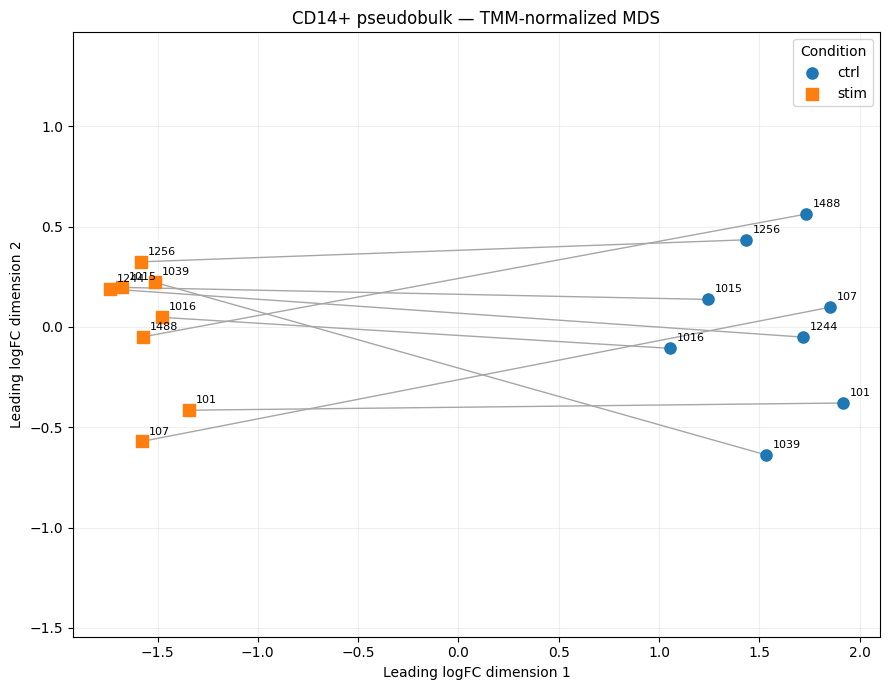

Paired TMM factor diagnostics:


condition,ctrl,stim,stim_over_ctrl_factor_ratio
donor_id,,,
101,1.2517,0.9518,0.7604
107,1.1309,0.8420,0.7445
1015,1.1821,0.8362,0.7074
1016,1.2342,0.9527,0.7719
1039,1.1517,0.8240,0.7154
1244,1.1738,0.7939,0.6764
1256,1.1130,0.8443,0.7585
1488,1.1142,0.8192,0.7353



MDS coordinates:


,sample_id,donor_id,condition,mds1,mds2,tmm_factor,effective_library_size
0,101__ctrl,101,ctrl,1.9185,-0.3793,1.2517,6.294339e+05
1,101__stim,101,stim,-1.3440,-0.4152,0.9518,6.727551e+05
2,107__ctrl,107,ctrl,1.8499,0.0976,1.1309,5.118335e+05
3,107__stim,107,stim,-1.5783,-0.5711,0.8420,3.586030e+05
4,1015__ctrl,1015,ctrl,1.2451,0.1370,1.1821,1.916325e+06
5,1015__stim,1015,stim,-1.6757,0.1969,0.8362,1.370567e+06
6,1016__ctrl,1016,ctrl,1.0546,-0.1068,1.2342,8.544031e+05
7,1016__stim,1016,stim,-1.4781,0.0476,0.9527,6.547502e+05
8,1039__ctrl,1039,ctrl,1.5336,-0.6382,1.1517,2.997014e+05
9,1039__stim,1039,stim,-1.5136,0.2221,0.8240,3.420296e+05



Saved figure: /kaggle/working/kang_ifnb/results/figures/stage05_cd14_pseudobulk_mds.png
Raw counts changed: NO
DE tests performed: 0

SAMPLE-LEVEL DIAGNOSTICS: PASS


In [13]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Load and validate MDS coordinates
# --------------------------------------------------

mds_table = pd.read_csv(
    R_MDS_OUTPUT,
    sep="\t",
    dtype={
        "sample_id": str,
        "donor_id": str,
        "condition": str,
    },
)

assert len(mds_table) == 16
assert mds_table["sample_id"].is_unique

assert mds_table["sample_id"].tolist() == (
    pb_filtered.obs_names.tolist()
)

assert np.isfinite(
    mds_table[["mds1", "mds2"]].to_numpy()
).all()

# Verify factor alignment
np.testing.assert_allclose(
    mds_table["tmm_factor"].to_numpy(),
    tmm_results["tmm_factor"].to_numpy(),
    rtol=1e-10,
    atol=1e-10,
)

# --------------------------------------------------
# 2. Prepare donor-paired coordinates
# --------------------------------------------------

donor_ids = sorted(
    mds_table["donor_id"].unique(),
    key=int,
)

paired_coordinates = mds_table.set_index(
    ["donor_id", "condition"]
)

assert len(donor_ids) == 8

# --------------------------------------------------
# 3. Plot MDS
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 7))

for donor in donor_ids:

    ctrl = paired_coordinates.loc[(donor, "ctrl")]
    stim = paired_coordinates.loc[(donor, "stim")]

    # Connect the two samples from the same donor
    ax.plot(
        [ctrl["mds1"], stim["mds1"]],
        [ctrl["mds2"], stim["mds2"]],
        color="0.65",
        linewidth=1,
        zorder=1,
    )

for condition, marker in [
    ("ctrl", "o"),
    ("stim", "s"),
]:
    subset = mds_table.loc[
        mds_table["condition"].eq(condition)
    ]

    ax.scatter(
        subset["mds1"],
        subset["mds2"],
        marker=marker,
        s=65,
        label=condition,
        zorder=2,
    )

    for _, row in subset.iterrows():
        ax.annotate(
            row["donor_id"],
            (row["mds1"], row["mds2"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8,
        )

ax.set_xlabel("Leading logFC dimension 1")
ax.set_ylabel("Leading logFC dimension 2")
ax.set_title(
    "CD14+ pseudobulk — TMM-normalized MDS"
)
ax.grid(alpha=0.2)
ax.legend(title="Condition")
ax.set_aspect("equal", adjustable="datalim")

fig.tight_layout()

FIGURES_DIR = PROJECT / "results" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

mds_figure_path = (
    FIGURES_DIR / "stage05_cd14_pseudobulk_mds.png"
)

fig.savefig(
    mds_figure_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# --------------------------------------------------
# 4. Compare paired TMM factors
# --------------------------------------------------

factor_pairs = (
    mds_table.pivot(
        index="donor_id",
        columns="condition",
        values="tmm_factor",
    )
    .loc[donor_ids, ["ctrl", "stim"]]
    .copy()
)

factor_pairs["stim_over_ctrl_factor_ratio"] = (
    factor_pairs["stim"] / factor_pairs["ctrl"]
)

assert factor_pairs.shape == (8, 3)

# Confirm the condition-associated pattern
assert (factor_pairs["ctrl"] > 1).all()
assert (factor_pairs["stim"] < 1).all()

print("Paired TMM factor diagnostics:")
display(factor_pairs.round(4))

print("\nMDS coordinates:")
display(mds_table.round(4))

# --------------------------------------------------
# 5. Save paired factor diagnostics
# --------------------------------------------------

factor_pairs.to_csv(
    AUDIT_DIR / "stage05_tmm_factors_by_donor.tsv",
    sep="\t",
)

# --------------------------------------------------
# 6. Verify original objects remain unchanged
# --------------------------------------------------

assert pb_filtered.shape == (16, 3697)
assert pb_filtered.layers["counts"].nnz == 58865

assert int(pb_filtered.layers["counts"].sum()) == 12177533

assert pb_full.shape == (16, 35635)
assert int(pb_full.layers["counts"].sum()) == 12580095

print("\nSaved figure:", mds_figure_path)
print("Raw counts changed: NO")
print("DE tests performed: 0")

print("\nSAMPLE-LEVEL DIAGNOSTICS: PASS")


## 6. Paired negative binomial quasi-likelihood model fitting

Fit the paired negative binomial quasi-likelihood model with a donor term.


In [14]:

import os
import subprocess
from pathlib import Path

# --------------------------------------------------
# 1. Output paths
# --------------------------------------------------

R_FIT_SCRIPT = AUDIT_DIR / "stage05_fit_paired_ql.R"

R_FIT_RDS = (
    PROJECT / "data" / "processed"
    / "ifnb_cd14_edger_paired_ql_fit.rds"
)

R_FIT_DIAGNOSTICS = (
    AUDIT_DIR / "stage05_ql_dispersion_diagnostics.tsv"
)

R_FIT_LOG = AUDIT_DIR / "stage05_paired_ql_fit.log"

QL_FIGURE = (
    PROJECT / "results" / "figures"
    / "stage05_ql_dispersion.png"
)

R_FIT_RDS.parent.mkdir(parents=True, exist_ok=True)
QL_FIGURE.parent.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 2. R script
# --------------------------------------------------

r_code = r'''
suppressPackageStartupMessages(library(edgeR))

args <- commandArgs(trailingOnly = TRUE)
stopifnot(length(args) == 4)

input_path <- args[1]
fit_path <- args[2]
diagnostics_path <- args[3]
figure_path <- args[4]

# -------------------------------------------
# Load verified TMM-normalized DGEList
# -------------------------------------------

saved <- readRDS(input_path)

y <- saved$y
meta <- saved$metadata

stopifnot(
    nrow(y$counts) == 3697,
    ncol(y$counts) == 16,
    sum(y$counts) == 12177533,
    identical(colnames(y$counts), meta$sample_id),
    all(is.finite(y$samples$norm.factors)),
    all(y$samples$norm.factors > 0)
)

counts_before <- y$counts
factors_before <- y$samples$norm.factors

# -------------------------------------------
# Define paired experimental design
# -------------------------------------------

donor_levels <- as.character(
    sort(unique(as.integer(meta$donor_id)))
)

meta$donor_id <- factor(
    as.character(meta$donor_id),
    levels = donor_levels
)

meta$condition <- factor(
    meta$condition,
    levels = c("ctrl", "stim")
)

stopifnot(
    length(donor_levels) == 8,
    all(!is.na(meta$donor_id)),
    all(!is.na(meta$condition))
)

pair_table <- table(
    meta$donor_id,
    meta$condition
)

stopifnot(
    identical(dim(pair_table), c(8L, 2L)),
    all(pair_table == 1L)
)

design <- model.matrix(
    ~ donor_id + condition,
    data = meta
)

stopifnot(
    identical(dim(design), c(16L, 9L)),
    qr(design)$rank == 9,
    "conditionstim" %in% colnames(design),
    nrow(design) - ncol(design) == 7
)

# -------------------------------------------
# Fit the new edgeR v4 QL model
# -------------------------------------------

fit <- edgeR::glmQLFit(
    y,
    design = design,
    robust = TRUE,
    legacy = FALSE
)

# No glmQLFTest is called in this step.

# -------------------------------------------
# Validate fitted model
# -------------------------------------------

stopifnot(
    identical(dim(fit$coefficients), c(3697L, 9L)),
    all(is.finite(fit$coefficients)),
    identical(colnames(fit$coefficients),
              colnames(design)),
    length(fit$s2.post) == 3697,
    all(is.finite(fit$s2.post)),
    all(fit$s2.post > 0),
    length(fit$df.residual.adj) == 3697,
    all(is.finite(fit$df.residual.adj)),
    all(fit$df.residual.adj >= 0),
    !anyNA(fit$df.prior),
    all(fit$df.prior >= 0),
    all(is.finite(fit$dispersion)),
    all(fit$dispersion > 0),
    identical(y$counts, counts_before),
    identical(y$samples$norm.factors, factors_before)
)

# -------------------------------------------
# Save gene-level dispersion diagnostics
# -------------------------------------------

diagnostics <- data.frame(
    gene_id = rownames(fit$coefficients),
    ave_log_cpm = fit$AveLogCPM,
    ql_dispersion_post = fit$s2.post,
    df_prior = fit$df.prior,
    df_residual_adj = fit$df.residual.adj
)

write.table(
    diagnostics,
    file = diagnostics_path,
    sep = "\t",
    row.names = FALSE,
    quote = FALSE
)

# -------------------------------------------
# Create quasi-likelihood dispersion plot
# -------------------------------------------

png(
    filename = figure_path,
    width = 1050,
    height = 780,
    res = 140
)

edgeR::plotQLDisp(fit)

dev.off()

# -------------------------------------------
# Preserve fitted model
# -------------------------------------------

saveRDS(
    list(
        y = y,
        fit = fit,
        design = design,
        metadata = meta,
        model_formula = "~ donor_id + condition",
        target_coefficient = "conditionstim",
        robust = TRUE,
        legacy = FALSE,
        de_test_performed = FALSE
    ),
    file = fit_path
)

# -------------------------------------------
# Print key diagnostics
# -------------------------------------------

cat(
    "EDGER_VERSION=",
    as.character(packageVersion("edgeR")),
    "\n",
    sep = ""
)

cat("DESIGN_DIMENSIONS=16x9\n")
cat("DESIGN_RANK=", qr(design)$rank, "\n", sep="")
cat("RESIDUAL_DF=7\n")
cat("TARGET_COEFFICIENT=conditionstim\n")

cat(
    "NB_DISPERSION=",
    paste(signif(fit$dispersion, 6), collapse=","),
    "\n",
    sep = ""
)

cat(
    "QL_POSTERIOR_DISPERSION_MEDIAN=",
    signif(median(fit$s2.post), 6),
    "\n",
    sep = ""
)

cat(
    "ADJUSTED_RESIDUAL_DF_RANGE=",
    paste(
        signif(range(fit$df.residual.adj), 6),
        collapse=","
    ),
    "\n",
    sep = ""
)

cat(
    "DF_PRIOR_SUMMARY=",
    paste(
        signif(
            as.numeric(quantile(
                fit$df.prior,
                probs = c(0, 0.5, 1)
            )),
            6
        ),
        collapse=","
    ),
    "\n",
    sep = ""
)

cat("DE_TESTS_PERFORMED=0\n")
cat("PAIRED QL MODEL FIT: PASS\n")
'''

R_FIT_SCRIPT.write_text(
    r_code,
    encoding="utf-8"
)

# --------------------------------------------------
# 3. Run R
# --------------------------------------------------

env = os.environ.copy()
env["R_LIBS_USER"] = str(R_LIB_DIR)

result = subprocess.run(
    [
        "Rscript",
        "--vanilla",
        str(R_FIT_SCRIPT),
        str(R_TMM_RDS),
        str(R_FIT_RDS),
        str(R_FIT_DIAGNOSTICS),
        str(QL_FIGURE),
    ],
    capture_output=True,
    text=True,
    env=env,
    timeout=300,
)

R_FIT_LOG.write_text(
    "STDOUT:\n" + result.stdout
    + "\nSTDERR:\n" + result.stderr,
    encoding="utf-8"
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr[-5000:])

assert result.returncode == 0
assert "PAIRED QL MODEL FIT: PASS" in result.stdout

assert R_FIT_RDS.is_file()
assert R_FIT_DIAGNOSTICS.is_file()
assert QL_FIGURE.is_file()

print("\nFitted model:", R_FIT_RDS)
print("Diagnostics:", R_FIT_DIAGNOSTICS)
print("Figure:", QL_FIGURE)

print("\nSTAGE 05 PAIRED QL FIT EXECUTION: PASS")


null device 
          1 
EDGER_VERSION=4.10.7
DESIGN_DIMENSIONS=16x9
DESIGN_RANK=9
RESIDUAL_DF=7
TARGET_COEFFICIENT=conditionstim
NB_DISPERSION=0.0418303
QL_POSTERIOR_DISPERSION_MEDIAN=0.606477
ADJUSTED_RESIDUAL_DF_RANGE=4.85786,16.8242
DF_PRIOR_SUMMARY=0.199419,9.44201,9.44201
DE_TESTS_PERFORMED=0
PAIRED QL MODEL FIT: PASS


Fitted model: /kaggle/working/kang_ifnb/data/processed/ifnb_cd14_edger_paired_ql_fit.rds
Diagnostics: /kaggle/working/kang_ifnb/results/audit/stage05_ql_dispersion_diagnostics.tsv
Figure: /kaggle/working/kang_ifnb/results/figures/stage05_ql_dispersion.png

STAGE 05 PAIRED QL FIT EXECUTION: PASS


Gene-level diagnostic summary:


,ave_log_cpm,ql_dispersion_post,df_prior,df_residual_adj
count,3697.0000,3697.0000,3697.0000,3697.0000
mean,6.0160,0.7298,9.3126,7.0477
std,1.7214,1.9341,0.9313,0.5817
min,3.8472,0.0477,0.1994,4.8579
25%,4.7319,0.4460,9.4420,6.9518
50%,5.5583,0.6065,9.4420,6.9889
75%,6.8308,0.7840,9.4420,6.9988
max,16.8901,69.9915,9.4420,16.8242



QL posterior dispersion quantiles:


,ql_dispersion_post
0.00,0.0477
0.25,0.4460
0.50,0.6065
0.75,0.7840
1.00,69.9915



Quasi-likelihood dispersion plot:


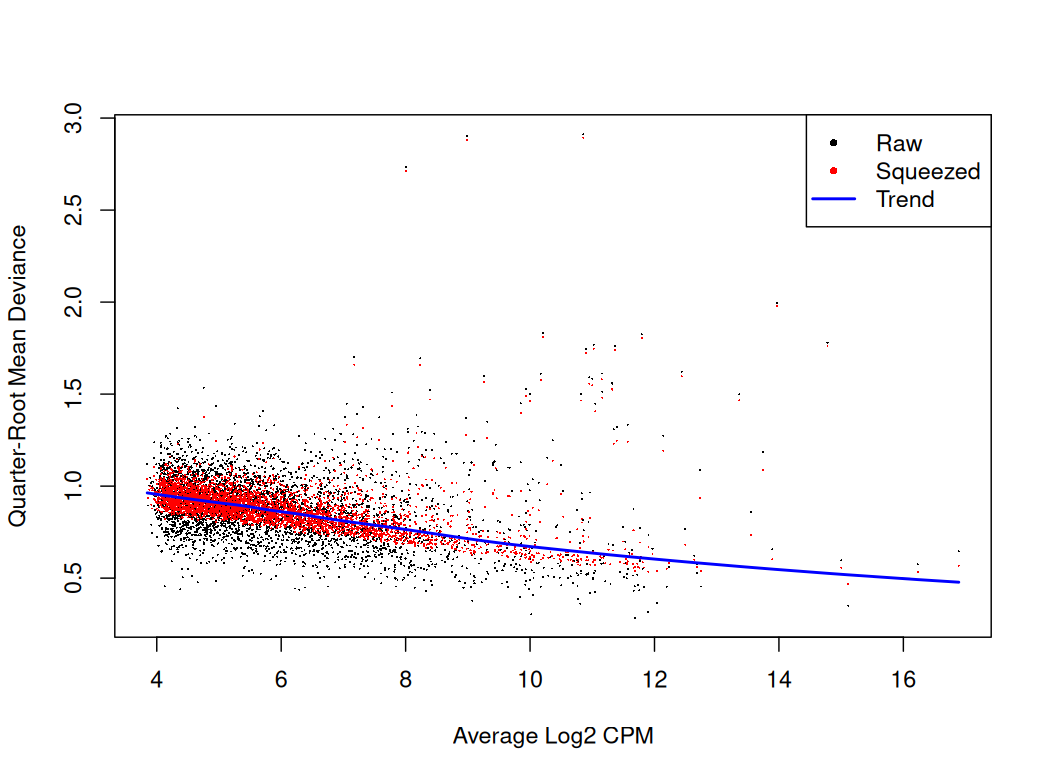


Raw counts changed: NO
Differential expression tests performed: 0

QL DISPERSION DIAGNOSTICS: PASS


In [15]:

import numpy as np
import pandas as pd
from IPython.display import display, Image

# --------------------------------------------------
# 1. Load gene-level diagnostics
# --------------------------------------------------

ql_diag = pd.read_csv(
    R_FIT_DIAGNOSTICS,
    sep="\t",
    dtype={"gene_id": str},
)

assert len(ql_diag) == 3697
assert ql_diag["gene_id"].is_unique

assert ql_diag["gene_id"].tolist() == (
    pb_filtered.var_names.astype(str).tolist()
)

# --------------------------------------------------
# 2. Validate numeric diagnostics
# --------------------------------------------------

for col in [
    "ave_log_cpm",
    "ql_dispersion_post",
    "df_residual_adj",
]:
    assert np.isfinite(
        ql_diag[col].to_numpy(dtype=float)
    ).all()

assert (
    ql_diag["ql_dispersion_post"] > 0
).all()

assert (
    ql_diag["df_residual_adj"] >= 0
).all()

assert not ql_diag["df_prior"].isna().any()
assert (ql_diag["df_prior"] >= 0).all()

# --------------------------------------------------
# 3. Summarize fitted model diagnostics
# --------------------------------------------------

summary_columns = [
    "ave_log_cpm",
    "ql_dispersion_post",
    "df_prior",
    "df_residual_adj",
]

print("Gene-level diagnostic summary:")
display(
    ql_diag[summary_columns]
    .describe()
    .round(4)
)

print("\nQL posterior dispersion quantiles:")
display(
    ql_diag["ql_dispersion_post"]
    .quantile([0, 0.25, 0.5, 0.75, 1])
    .round(4)
    .rename("ql_dispersion_post")
    .to_frame()
)

# --------------------------------------------------
# 4. Display dispersion plot
# --------------------------------------------------

print("\nQuasi-likelihood dispersion plot:")
display(
    Image(filename=str(QL_FIGURE))
)

# --------------------------------------------------
# 5. Confirm count inputs remain unchanged
# --------------------------------------------------

assert pb_filtered.shape == (16, 3697)
assert int(pb_filtered.layers["counts"].sum()) == 12177533

assert pb_full.shape == (16, 35635)
assert int(pb_full.layers["counts"].sum()) == 12580095

print("\nRaw counts changed: NO")
print("Differential expression tests performed: 0")

print("\nQL DISPERSION DIAGNOSTICS: PASS")


## 7. Paired quasi-likelihood differential expression test

Test the stimulated coefficient and apply Benjamini–Hochberg correction across tested genes.


In [16]:

import os
import subprocess

# --------------------------------------------------
# 1. Define paths
# --------------------------------------------------

R_QLF_SCRIPT = (
    AUDIT_DIR / "stage05_paired_qlf_test.R"
)

R_QLF_RESULTS = (
    DE_DIR / "stage05_paired_qlf_all_genes.tsv"
)

R_QLF_RDS = (
    PROJECT / "data" / "processed"
    / "ifnb_cd14_edger_paired_qlf.rds"
)

R_QLF_LOG = (
    AUDIT_DIR / "stage05_paired_qlf_test.log"
)

DE_DIR.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 2. R test script
# --------------------------------------------------

r_code = r'''
suppressPackageStartupMessages(library(edgeR))

args <- commandArgs(trailingOnly = TRUE)
stopifnot(length(args) == 3)

fit_path <- args[1]
result_path <- args[2]
test_rds_path <- args[3]

# -------------------------------------------
# Load the previously fitted model
# -------------------------------------------

saved <- readRDS(fit_path)

y <- saved$y
fit <- saved$fit
design <- saved$design

stopifnot(
    isFALSE(saved$de_test_performed),
    nrow(y$counts) == 3697,
    ncol(y$counts) == 16,
    sum(y$counts) == 12177533,
    identical(dim(design), c(16L, 9L)),
    qr(design)$rank == 9,
    identical(colnames(fit$coefficients),
              colnames(design)),
    "conditionstim" %in% colnames(design)
)

# -------------------------------------------
# Test the pre-specified coefficient
# -------------------------------------------

qlf <- edgeR::glmQLFTest(
    fit,
    coef = "conditionstim"
)

tbl <- qlf$table

required_cols <- c(
    "logFC", "logCPM", "F", "PValue"
)

stopifnot(
    nrow(tbl) == 3697,
    all(required_cols %in% colnames(tbl)),
    identical(rownames(tbl), rownames(y$counts)),
    all(is.finite(as.matrix(
        tbl[, required_cols, drop=FALSE]
    ))),
    all(tbl$F >= 0),
    all(tbl$PValue >= 0),
    all(tbl$PValue <= 1)
)

# -------------------------------------------
# Benjamini-Hochberg FDR
# -------------------------------------------

fdr <- p.adjust(
    tbl$PValue,
    method = "BH"
)

stopifnot(
    length(fdr) == 3697,
    all(is.finite(fdr)),
    all(fdr >= 0),
    all(fdr <= 1)
)

# -------------------------------------------
# Export ALL genes in original order
# -------------------------------------------

results <- data.frame(
    gene_id = rownames(tbl),
    logFC = tbl$logFC,
    logCPM = tbl$logCPM,
    F = tbl$F,
    PValue = tbl$PValue,
    FDR = fdr
)

options(digits = 17)

write.table(
    results,
    file = result_path,
    sep = "\t",
    quote = FALSE,
    row.names = FALSE
)

# Preserve the actual test object.
saveRDS(
    list(
        test = qlf,
        coefficient = "conditionstim",
        fdr_method = "BH",
        fdr_threshold = 0.05,
        n_genes_tested = 3697,
        source_fit = basename(fit_path),
        interpretation_limit =
            "condition is confounded with pooled capture"
    ),
    file = test_rds_path
)

# -------------------------------------------
# Report descriptive results
# -------------------------------------------

sig <- fdr < 0.05

cat("EDGER_VERSION=",
    as.character(packageVersion("edgeR")),
    "\n", sep = "")

cat("TEST_COEFFICIENT=conditionstim\n")
cat("TEST_DIRECTION=stim_vs_ctrl\n")
cat("GENES_TESTED=", length(fdr), "\n", sep = "")

cat("FDR_LT_0.05=", sum(sig), "\n", sep = "")

cat(
    "FDR_LT_0.05_POSITIVE_LOGFC=",
    sum(sig & tbl$logFC > 0),
    "\n",
    sep = ""
)

cat(
    "FDR_LT_0.05_NEGATIVE_LOGFC=",
    sum(sig & tbl$logFC < 0),
    "\n",
    sep = ""
)

cat("PAIRED QLF TEST: PASS\n")
'''

R_QLF_SCRIPT.write_text(
    r_code,
    encoding="utf-8"
)

# --------------------------------------------------
# 3. Run edgeR
# --------------------------------------------------

env = os.environ.copy()
env["R_LIBS_USER"] = str(R_LIB_DIR)

result = subprocess.run(
    [
        "Rscript",
        "--vanilla",
        str(R_QLF_SCRIPT),
        str(R_FIT_RDS),
        str(R_QLF_RESULTS),
        str(R_QLF_RDS),
    ],
    capture_output=True,
    text=True,
    env=env,
    timeout=300,
)

R_QLF_LOG.write_text(
    "STDOUT:\n" + result.stdout
    + "\nSTDERR:\n" + result.stderr,
    encoding="utf-8",
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr[-5000:])

assert result.returncode == 0
assert "PAIRED QLF TEST: PASS" in result.stdout

assert R_QLF_RESULTS.is_file()
assert R_QLF_RDS.is_file()

print("\nDE table:", R_QLF_RESULTS)
print("Test object:", R_QLF_RDS)

print("\nSTAGE 05 PAIRED QLF TEST EXECUTION: PASS")


EDGER_VERSION=4.10.7
TEST_COEFFICIENT=conditionstim
TEST_DIRECTION=stim_vs_ctrl
GENES_TESTED=3697
FDR_LT_0.05=2502
FDR_LT_0.05_POSITIVE_LOGFC=1250
FDR_LT_0.05_NEGATIVE_LOGFC=1252
PAIRED QLF TEST: PASS


DE table: /kaggle/working/kang_ifnb/results/de/stage05_paired_qlf_all_genes.tsv
Test object: /kaggle/working/kang_ifnb/data/processed/ifnb_cd14_edger_paired_qlf.rds

STAGE 05 PAIRED QLF TEST EXECUTION: PASS


In [17]:

import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Load full DE results
# --------------------------------------------------

de_results = pd.read_csv(
    R_QLF_RESULTS,
    sep="\t",
    dtype={"gene_id": str},
)

required_columns = [
    "gene_id",
    "logFC",
    "logCPM",
    "F",
    "PValue",
    "FDR",
]

assert de_results.columns.tolist() == required_columns
assert len(de_results) == 3697
assert de_results["gene_id"].is_unique

# Same gene IDs and same order as filtered AnnData
assert de_results["gene_id"].tolist() == (
    pb_filtered.var_names.astype(str).tolist()
)

# --------------------------------------------------
# 2. Verify test statistics
# --------------------------------------------------

numeric_cols = [
    "logFC", "logCPM", "F", "PValue", "FDR"
]

assert np.isfinite(
    de_results[numeric_cols].to_numpy(dtype=float)
).all()

assert (de_results["F"] >= 0).all()

assert de_results["PValue"].between(0, 1).all()
assert de_results["FDR"].between(0, 1).all()

# --------------------------------------------------
# 3. Independently recompute BH adjustment
# --------------------------------------------------

p = de_results["PValue"].to_numpy(dtype=float)
m = len(p)

order = np.argsort(p, kind="stable")
p_sorted = p[order]

q_sorted = (
    p_sorted * m / np.arange(1, m + 1)
)

q_sorted = np.minimum.accumulate(
    q_sorted[::-1]
)[::-1]

q_sorted = np.clip(q_sorted, 0, 1)

bh_python = np.empty(m, dtype=float)
bh_python[order] = q_sorted

np.testing.assert_allclose(
    bh_python,
    de_results["FDR"].to_numpy(dtype=float),
    rtol=1e-8,
    atol=1e-10,
)

print("Benjamini-Hochberg FDR: EXACT NUMERICAL CHECK")

# --------------------------------------------------
# 4. Add gene symbols using Ensembl IDs
# --------------------------------------------------

gene_symbol_map = (
    pb_filtered.var["gene_symbol"]
    .astype("string")
)

de_results["gene_symbol"] = (
    gene_symbol_map
    .reindex(de_results["gene_id"])
    .to_numpy()
)

# Keep Ensembl ID as the unique identifier.
assert de_results["gene_id"].is_unique

# --------------------------------------------------
# 5. Summarize FDR-based discoveries
# --------------------------------------------------

sig = de_results["FDR"] < 0.05

n_sig = int(sig.sum())
n_up = int(
    (sig & (de_results["logFC"] > 0)).sum()
)
n_down = int(
    (sig & (de_results["logFC"] < 0)).sum()
)

assert n_up + n_down <= n_sig

print("\nGenes tested:", len(de_results))
print("FDR < 0.05:", n_sig)
print("Positive logFC:", n_up)
print("Negative logFC:", n_down)

# --------------------------------------------------
# 6. Inspect top-ranked genes
# --------------------------------------------------

ranked_results = de_results.sort_values(
    ["FDR", "PValue", "gene_id"],
    ascending=[True, True, True]
)

print("\nTop 15 genes by FDR and p-value:")

display(
    ranked_results[
        [
            "gene_id",
            "gene_symbol",
            "logFC",
            "logCPM",
            "F",
            "PValue",
            "FDR",
        ]
    ]
    .head(15)
    .round(5)
)

# --------------------------------------------------
# 7. Save annotated results without dropping genes
# --------------------------------------------------

annotated_path = (
    DE_DIR
    / "stage05_paired_qlf_all_genes_annotated.tsv.gz"
)

de_results.to_csv(
    annotated_path,
    sep="\t",
    index=False,
    compression="gzip",
)

# --------------------------------------------------
# 8. Verify original data were not modified
# --------------------------------------------------

assert pb_filtered.shape == (16, 3697)

assert int(
    pb_filtered.layers["counts"].sum()
) == 12177533

assert pb_full.shape == (16, 35635)

assert int(
    pb_full.layers["counts"].sum()
) == 12580095

print("\nAnnotated DE table:", annotated_path)
print("Genes removed from result table: 0")
print("Raw UMI counts changed: NO")

print("\nPAIRED QLF RESULTS VALIDATION: PASS")


Benjamini-Hochberg FDR: EXACT NUMERICAL CHECK

Genes tested: 3697
FDR < 0.05: 2502
Positive logFC: 1250
Negative logFC: 1252

Top 15 genes by FDR and p-value:


,gene_id,gene_symbol,logFC,logCPM,F,PValue,FDR
1309,ENSG00000111912,NCOA7,6.66504,5.67881,553.38862,0.0,0.0
159,ENSG00000162614,NEXN,6.65896,6.20548,548.42965,0.0,0.0
1161,ENSG00000137198,GMPR,7.01149,7.02392,765.36377,0.0,0.0
870,ENSG00000004468,CD38,7.19054,7.46618,773.84507,0.0,0.0
1384,ENSG00000122643,NT5C3A,5.78056,8.32976,1450.07277,0.0,0.0
729,ENSG00000163666,HESX1,8.57763,6.77599,555.04348,0.0,0.0
2060,ENSG00000185885,IFITM1,6.12384,6.32676,608.95417,0.0,0.0
1337,ENSG00000146425,DYNLT1,2.71447,10.42108,1083.02551,0.0,0.0
2840,ENSG00000176046,NUPR1,8.16450,6.34786,517.14274,0.0,0.0
563,ENSG00000138385,SSB,3.38499,9.06927,988.25731,0.0,0.0



Annotated DE table: /kaggle/working/kang_ifnb/results/de/stage05_paired_qlf_all_genes_annotated.tsv.gz
Genes removed from result table: 0
Raw UMI counts changed: NO

PAIRED QLF RESULTS VALIDATION: PASS


## 8. Gene-level and paired-donor DE diagnostics

Check p-value precision and compute paired differences in TMM-normalized log2 CPM.


In [18]:

import os
import subprocess

# --------------------------------------------------
# 1. Output paths
# --------------------------------------------------

R_LOGCPM_SCRIPT = (
    AUDIT_DIR / "stage05_export_tmm_logcpm.R"
)

R_LOGCPM_OUTPUT = (
    AUDIT_DIR / "stage05_tmm_logcpm.tsv.gz"
)

R_LOGCPM_LOG = (
    AUDIT_DIR / "stage05_export_tmm_logcpm.log"
)

# --------------------------------------------------
# 2. Create R script
# --------------------------------------------------

r_code = r'''
suppressPackageStartupMessages(library(edgeR))

args <- commandArgs(trailingOnly = TRUE)
stopifnot(length(args) == 2)

input_path <- args[1]
output_path <- args[2]

saved <- readRDS(input_path)
y <- saved$y
meta <- saved$metadata

stopifnot(
    nrow(y$counts) == 3697,
    ncol(y$counts) == 16,
    sum(y$counts) == 12177533,
    identical(colnames(y$counts), meta$sample_id)
)

counts_before <- y$counts

# Use the TMM-normalized effective library sizes
logcpm <- edgeR::cpm(
    y,
    normalized.lib.sizes = TRUE,
    log = TRUE,
    prior.count = 2
)

stopifnot(
    identical(dim(logcpm), c(3697L, 16L)),
    identical(rownames(logcpm), rownames(y$counts)),
    identical(colnames(logcpm), colnames(y$counts)),
    all(is.finite(logcpm)),
    identical(y$counts, counts_before)
)

# Preserve gene and sample IDs
export <- data.frame(
    gene_id = rownames(logcpm),
    logcpm,
    check.names = FALSE
)

options(digits = 17)

con <- gzfile(output_path, open = "wt")

write.table(
    export,
    file = con,
    sep = "\t",
    quote = FALSE,
    row.names = FALSE
)

close(con)

cat("LOGCPM_NORMALIZATION=TMM\n")
cat("LOGCPM_PRIOR_COUNT=2\n")
cat("LOGCPM_GENES=", nrow(logcpm), "\n", sep="")
cat("LOGCPM_SAMPLES=", ncol(logcpm), "\n", sep="")
cat("RAW_COUNT_SUM=", sum(y$counts), "\n", sep="")

cat("TMM LOGCPM EXPORT: PASS\n")
'''

R_LOGCPM_SCRIPT.write_text(
    r_code,
    encoding="utf-8"
)

# --------------------------------------------------
# 3. Execute R script
# --------------------------------------------------

env = os.environ.copy()
env["R_LIBS_USER"] = str(R_LIB_DIR)

result = subprocess.run(
    [
        "Rscript",
        "--vanilla",
        str(R_LOGCPM_SCRIPT),
        str(R_TMM_RDS),
        str(R_LOGCPM_OUTPUT),
    ],
    capture_output=True,
    text=True,
    env=env,
    timeout=180,
)

R_LOGCPM_LOG.write_text(
    "STDOUT:\n" + result.stdout
    + "\nSTDERR:\n" + result.stderr,
    encoding="utf-8"
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr[-4000:])

assert result.returncode == 0
assert "TMM LOGCPM EXPORT: PASS" in result.stdout
assert R_LOGCPM_OUTPUT.is_file()

print("\nOutput:", R_LOGCPM_OUTPUT)
print("\nSTAGE 05 LOGCPM EXPORT: PASS")


LOGCPM_NORMALIZATION=TMM
LOGCPM_PRIOR_COUNT=2
LOGCPM_GENES=3697
LOGCPM_SAMPLES=16
RAW_COUNT_SUM=12177533
TMM LOGCPM EXPORT: PASS


Output: /kaggle/working/kang_ifnb/results/audit/stage05_tmm_logcpm.tsv.gz

STAGE 05 LOGCPM EXPORT: PASS


In [19]:

import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Audit original p-values and FDR precision
# --------------------------------------------------

assert len(de_results) == 3697

pvalues = de_results["PValue"].to_numpy(dtype=float)
fdr_values = de_results["FDR"].to_numpy(dtype=float)

n_zero_p = int(np.count_nonzero(pvalues == 0))
n_zero_fdr = int(np.count_nonzero(fdr_values == 0))

positive_p = pvalues[pvalues > 0]
positive_fdr = fdr_values[fdr_values > 0]

print("P-values stored as exact zero:", n_zero_p)
print("FDR values stored as exact zero:", n_zero_fdr)

if positive_p.size:
    print(
        "Smallest positive PValue:",
        f"{positive_p.min():.8e}"
    )

if positive_fdr.size:
    print(
        "Smallest positive FDR:",
        f"{positive_fdr.min():.8e}"
    )

if n_zero_p or n_zero_fdr:
    print(
        "WARNING: Exact numeric zeros detected. "
        "Inspect possible numerical underflow before "
        "using -log10(PValue) or -log10(FDR)."
    )

# --------------------------------------------------
# 2. Load TMM-normalized log2-CPM
# --------------------------------------------------

logcpm_df = pd.read_csv(
    R_LOGCPM_OUTPUT,
    sep="\t",
    dtype={"gene_id": str},
)

assert logcpm_df.shape == (3697, 17)

assert logcpm_df["gene_id"].tolist() == (
    pb_filtered.var_names.astype(str).tolist()
)

sample_ids = pb_filtered.obs_names.tolist()

assert logcpm_df.columns[1:].tolist() == sample_ids

logcpm = logcpm_df.set_index("gene_id")

assert np.isfinite(logcpm.to_numpy(dtype=float)).all()

# --------------------------------------------------
# 3. Calculate paired log2-CPM differences
# --------------------------------------------------

donors = sorted(
    pb_filtered.obs["donor_id"]
    .astype(str)
    .unique(),
    key=int,
)

assert len(donors) == 8

paired_differences = pd.DataFrame(
    index=logcpm.index
)

for donor in donors:

    ctrl_id = f"{donor}__ctrl"
    stim_id = f"{donor}__stim"

    assert ctrl_id in logcpm.columns
    assert stim_id in logcpm.columns

    paired_differences[donor] = (
        logcpm[stim_id] - logcpm[ctrl_id]
    )

assert paired_differences.shape == (3697, 8)

delta = paired_differences.to_numpy(dtype=float)

# --------------------------------------------------
# 4. Compare donor directions with model logFC
# --------------------------------------------------

model_logfc = (
    de_results["logFC"].to_numpy(dtype=float)
)

assert np.isfinite(model_logfc).all()

direction = np.sign(model_logfc)[:, None]

matching = delta * direction > 0
opposing = delta * direction < 0

n_matching = matching.sum(axis=1)
n_opposing = opposing.sum(axis=1)
n_ties = 8 - n_matching - n_opposing

# --------------------------------------------------
# 5. Build a reproducible gene-level audit
# --------------------------------------------------

paired_audit = de_results[
    ["gene_id", "gene_symbol", "logFC",
     "PValue", "FDR"]
].copy()

paired_audit["mean_paired_delta_logCPM"] = (
    delta.mean(axis=1)
)

paired_audit["median_paired_delta_logCPM"] = (
    np.median(delta, axis=1)
)

paired_audit["n_donors_matching_logFC"] = (
    n_matching
)

paired_audit["n_donors_opposing_logFC"] = (
    n_opposing
)

paired_audit["n_donors_tied"] = n_ties

assert paired_audit["gene_id"].tolist() == (
    de_results["gene_id"].tolist()
)

assert (
    paired_audit[
        [
            "n_donors_matching_logFC",
            "n_donors_opposing_logFC",
            "n_donors_tied",
        ]
    ].sum(axis=1) == 8
).all()

# --------------------------------------------------
# 6. Summarize significant genes
# --------------------------------------------------

sig = paired_audit["FDR"] < 0.05

n_sig = int(sig.sum())
assert n_sig == 2502

print("\nSignificant genes:", n_sig)

print(
    "8/8 donors matching logFC:",
    int((sig & (n_matching == 8)).sum())
)

print(
    "At least 7/8 donors matching:",
    int((sig & (n_matching >= 7)).sum())
)

print(
    "At least 6/8 donors matching:",
    int((sig & (n_matching >= 6)).sum())
)

print(
    "At most 4/8 donors matching:",
    int((sig & (n_matching <= 4)).sum())
)

# --------------------------------------------------
# 7. Inspect top 15 genes
# --------------------------------------------------

ranked = paired_audit.sort_values(
    ["FDR", "PValue", "gene_id"]
)

top15 = ranked.head(15).copy()

print("\nTop 15 genes: paired donor consistency")

display(
    top15[
        [
            "gene_symbol",
            "logFC",
            "mean_paired_delta_logCPM",
            "n_donors_matching_logFC",
            "n_donors_opposing_logFC",
            "PValue",
            "FDR",
        ]
    ].round({
        "logFC": 3,
        "mean_paired_delta_logCPM": 3,
    })
    .assign(
        PValue=lambda x: x["PValue"].map(
            lambda v: f"{v:.3e}"
        ),
        FDR=lambda x: x["FDR"].map(
            lambda v: f"{v:.3e}"
        ),
    )
)

# --------------------------------------------------
# 8. Save diagnostics without altering DE results
# --------------------------------------------------

audit_path = (
    AUDIT_DIR
    / "stage05_paired_donor_de_consistency.tsv.gz"
)

paired_audit.to_csv(
    audit_path,
    sep="\t",
    index=False
)

paired_differences.to_csv(
    AUDIT_DIR
    / "stage05_paired_donor_logcpm_differences.tsv.gz",
    sep="\t",
    index_label="gene_id"
)

# --------------------------------------------------
# 9. Ensure primary results are unchanged
# --------------------------------------------------

assert len(de_results) == 3697
assert int((de_results["FDR"] < 0.05).sum()) == 2502

assert pb_filtered.shape == (16, 3697)
assert int(pb_filtered.layers["counts"].sum()) == 12177533

print("\nDiagnostics:", audit_path)
print("DE results modified: NO")
print("Raw counts modified: NO")

print("\nPAIRED DONOR CONSISTENCY AUDIT: PASS")


P-values stored as exact zero: 0
FDR values stored as exact zero: 0
Smallest positive PValue: 2.78123382e-18
Smallest positive FDR: 4.58160820e-15

Significant genes: 2502
8/8 donors matching logFC: 1795
At least 7/8 donors matching: 2339
At least 6/8 donors matching: 2488
At most 4/8 donors matching: 0

Top 15 genes: paired donor consistency


,gene_symbol,logFC,mean_paired_delta_logCPM,n_donors_matching_logFC,n_donors_opposing_logFC,PValue,FDR
1309,NCOA7,6.665,4.915,8,0,2.781e-18,4.582e-15
159,NEXN,6.659,5.355,8,0,2.841e-18,4.582e-15
1161,GMPR,7.011,6.098,8,0,3.718e-18,4.582e-15
870,CD38,7.191,6.244,8,0,9.574e-18,8.849e-15
1384,NT5C3A,5.781,5.615,8,0,2.185e-17,1.615e-14
729,HESX1,8.578,6.197,8,0,6.326e-17,3.898e-14
2060,IFITM1,6.124,5.214,8,0,1.149e-16,6.069e-14
1337,DYNLT1,2.714,2.707,8,0,1.927e-16,8.904e-14
2840,NUPR1,8.164,5.658,8,0,3.350e-16,1.361e-13
563,SSB,3.385,3.364,8,0,4.054e-16,1.361e-13



Diagnostics: /kaggle/working/kang_ifnb/results/audit/stage05_paired_donor_de_consistency.tsv.gz
DE results modified: NO
Raw counts modified: NO

PAIRED DONOR CONSISTENCY AUDIT: PASS


## 9. Leave-one-donor-out sensitivity analysis

Omit one complete donor pair per refit and compare the resulting effect sizes and FDR.


In [20]:

import os
import subprocess

R_LODO_SCRIPT = AUDIT_DIR / "stage05_lodo_analysis.R"

R_LODO_GENES = (
    AUDIT_DIR / "stage05_lodo_all_folds.tsv.gz"
)

R_LODO_SUMMARY = (
    AUDIT_DIR / "stage05_lodo_fold_summary.tsv"
)

R_LODO_LOG = (
    AUDIT_DIR / "stage05_lodo_analysis.log"
)

r_code = r'''
suppressPackageStartupMessages(library(edgeR))

args <- commandArgs(trailingOnly=TRUE)
stopifnot(length(args) == 3)

saved <- readRDS(args[1])
gene_output <- args[2]
summary_output <- args[3]

counts <- saved$y$counts
meta <- saved$metadata

stopifnot(
    identical(dim(counts), c(3697L, 16L)),
    sum(counts) == 12177533,
    identical(colnames(counts), meta$sample_id)
)

meta$donor_id <- as.character(meta$donor_id)
meta$condition <- as.character(meta$condition)

donors <- as.character(
    sort(unique(as.integer(meta$donor_id)))
)

stopifnot(length(donors) == 8)

gene_results <- vector("list", length(donors))
fold_results <- vector("list", length(donors))

for (k in seq_along(donors)) {

    omitted <- donors[k]

    # 1. Remove the entire donor pair
    keep_samples <- meta$donor_id != omitted

    sub_meta <- meta[keep_samples, , drop=FALSE]
    sub_counts <- counts[, keep_samples, drop=FALSE]

    stopifnot(
        identical(dim(sub_counts), c(3697L, 14L)),
        identical(colnames(sub_counts),
                  sub_meta$sample_id),
        all(rowSums(sub_counts) > 0)
    )

    sub_meta$donor_id <- factor(
        sub_meta$donor_id,
        levels=as.character(
            sort(unique(as.integer(
                sub_meta$donor_id
            )))
        )
    )

    sub_meta$condition <- factor(
        sub_meta$condition,
        levels=c("ctrl", "stim")
    )

    stopifnot(
        identical(
            dim(table(
                sub_meta$donor_id,
                sub_meta$condition
            )),
            c(7L, 2L)
        ),
        all(table(
            sub_meta$donor_id,
            sub_meta$condition
        ) == 1L)
    )

    # 2. Recreate DGEList from raw filtered counts
    y_sub <- edgeR::DGEList(
        counts=sub_counts,
        group=sub_meta$condition
    )

    # 3. Recalculate TMM from scratch
    y_sub <- edgeR::normLibSizes(
        y_sub,
        method="TMM"
    )

    stopifnot(
        all(y_sub$samples$norm.factors > 0),
        all(is.finite(y_sub$samples$norm.factors)),
        all(y_sub$samples$lib.size == colSums(sub_counts)),
        identical(y_sub$counts, sub_counts)
    )

    # 4. Rebuild the paired design
    design_sub <- model.matrix(
        ~ donor_id + condition,
        data=sub_meta
    )

    stopifnot(
        identical(dim(design_sub), c(14L, 8L)),
        qr(design_sub)$rank == 8L,
        "conditionstim" %in% colnames(design_sub)
    )

    # 5. Refit the edgeR v4 QL model
    fit_sub <- edgeR::glmQLFit(
        y_sub,
        design=design_sub,
        robust=TRUE,
        legacy=FALSE
    )

    test_sub <- edgeR::glmQLFTest(
        fit_sub,
        coef="conditionstim"
    )

    tbl <- test_sub$table

    stopifnot(
        nrow(tbl) == 3697,
        identical(rownames(tbl), rownames(counts)),
        all(is.finite(tbl$logFC)),
        all(is.finite(tbl$PValue)),
        all(tbl$PValue >= 0),
        all(tbl$PValue <= 1)
    )

    fdr <- p.adjust(tbl$PValue, method="BH")

    # 6. Save ALL genes from this fold
    gene_results[[k]] <- data.frame(
        omitted_donor=omitted,
        gene_id=rownames(tbl),
        logFC=tbl$logFC,
        PValue=tbl$PValue,
        FDR=fdr
    )

    fold_results[[k]] <- data.frame(
        omitted_donor=omitted,
        n_donors=7L,
        n_samples=14L,
        n_genes=3697L,
        design_rank=qr(design_sub)$rank,
        residual_df=nrow(design_sub)-ncol(design_sub),
        n_fdr05=sum(fdr < 0.05),
        nb_dispersion=median(fit_sub$dispersion),
        min_tmm_factor=min(y_sub$samples$norm.factors),
        max_tmm_factor=max(y_sub$samples$norm.factors)
    )

    cat(
        "OMITTED_DONOR=", omitted,
        " GENES=3697",
        " FDR_LT_0.05=", sum(fdr < 0.05),
        " FIT=PASS\n",
        sep=""
    )
}

# 7. Export results with numerical precision
all_genes <- do.call(rbind, gene_results)
all_folds <- do.call(rbind, fold_results)

stopifnot(
    nrow(all_genes) == 8L * 3697L,
    nrow(all_folds) == 8L,
    all(all_folds$residual_df == 6L),
    all(all_folds$design_rank == 8L)
)

options(digits=17)

con <- gzfile(gene_output, open="wt")
write.table(
    all_genes,
    file=con,
    sep="\t",
    quote=FALSE,
    row.names=FALSE
)
close(con)

write.table(
    all_folds,
    file=summary_output,
    sep="\t",
    quote=FALSE,
    row.names=FALSE
)

# 8. Verify original objects were untouched
stopifnot(
    identical(saved$y$counts, counts),
    sum(saved$y$counts) == 12177533
)

cat("LODO_FOLDS_COMPLETED=8\n")
cat("LODO_TOTAL_GENE_RESULTS=", nrow(all_genes), "\n", sep="")
cat("LODO EDGER EXECUTION: PASS\n")
'''

R_LODO_SCRIPT.write_text(
    r_code,
    encoding="utf-8"
)

env = os.environ.copy()
env["R_LIBS_USER"] = str(R_LIB_DIR)

result = subprocess.run(
    [
        "Rscript",
        "--vanilla",
        str(R_LODO_SCRIPT),
        str(R_FIT_RDS),
        str(R_LODO_GENES),
        str(R_LODO_SUMMARY),
    ],
    capture_output=True,
    text=True,
    env=env,
    timeout=900,
)

R_LODO_LOG.write_text(
    "STDOUT:\n" + result.stdout
    + "\nSTDERR:\n" + result.stderr,
    encoding="utf-8"
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr[-5000:])

assert result.returncode == 0
assert "LODO EDGER EXECUTION: PASS" in result.stdout
assert R_LODO_GENES.is_file()
assert R_LODO_SUMMARY.is_file()

print("\nGene-level output:", R_LODO_GENES)
print("Fold summary:", R_LODO_SUMMARY)

print("\nSTAGE 05 LODO EXECUTION: PASS")


OMITTED_DONOR=101 GENES=3697 FDR_LT_0.05=2414 FIT=PASS
OMITTED_DONOR=107 GENES=3697 FDR_LT_0.05=2429 FIT=PASS
OMITTED_DONOR=1015 GENES=3697 FDR_LT_0.05=2337 FIT=PASS
OMITTED_DONOR=1016 GENES=3697 FDR_LT_0.05=2434 FIT=PASS
OMITTED_DONOR=1039 GENES=3697 FDR_LT_0.05=2448 FIT=PASS
OMITTED_DONOR=1244 GENES=3697 FDR_LT_0.05=2374 FIT=PASS
OMITTED_DONOR=1256 GENES=3697 FDR_LT_0.05=2445 FIT=PASS
OMITTED_DONOR=1488 GENES=3697 FDR_LT_0.05=2452 FIT=PASS
LODO_FOLDS_COMPLETED=8
LODO_TOTAL_GENE_RESULTS=29576
LODO EDGER EXECUTION: PASS


Gene-level output: /kaggle/working/kang_ifnb/results/audit/stage05_lodo_all_folds.tsv.gz
Fold summary: /kaggle/working/kang_ifnb/results/audit/stage05_lodo_fold_summary.tsv

STAGE 05 LODO EXECUTION: PASS


In [21]:

import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Load and validate all eight LODO fits
# --------------------------------------------------

lodo = pd.read_csv(
    R_LODO_GENES,
    sep="\t",
    dtype={
        "omitted_donor": str,
        "gene_id": str,
    },
)

fold_summary = pd.read_csv(
    R_LODO_SUMMARY,
    sep="\t",
    dtype={"omitted_donor": str},
)

donor_order = sorted(
    pb_filtered.obs["donor_id"]
    .astype(str)
    .unique(),
    key=int,
)

assert len(donor_order) == 8
assert lodo.shape[0] == 8 * 3697
assert len(fold_summary) == 8

assert set(lodo["omitted_donor"]) == set(donor_order)
assert set(fold_summary["omitted_donor"]) == set(donor_order)

assert not lodo.duplicated(
    ["omitted_donor", "gene_id"]
).any()

assert (fold_summary["n_donors"] == 7).all()
assert (fold_summary["n_samples"] == 14).all()
assert (fold_summary["design_rank"] == 8).all()
assert (fold_summary["residual_df"] == 6).all()

for donor in donor_order:
    block = lodo.loc[
        lodo["omitted_donor"].eq(donor)
    ]
    assert block["gene_id"].tolist() == (
        de_results["gene_id"].tolist()
    )

assert np.isfinite(
    lodo[["logFC", "PValue", "FDR"]]
    .to_numpy(dtype=float)
).all()

assert lodo["PValue"].between(0, 1).all()
assert lodo["FDR"].between(0, 1).all()

# --------------------------------------------------
# 2. Pivot gene-level LODO estimates
# --------------------------------------------------

gene_order = de_results["gene_id"].tolist()

loo_logfc = (
    lodo.pivot(
        index="gene_id",
        columns="omitted_donor",
        values="logFC",
    )
    .reindex(
        index=gene_order,
        columns=donor_order,
    )
)

loo_fdr = (
    lodo.pivot(
        index="gene_id",
        columns="omitted_donor",
        values="FDR",
    )
    .reindex(
        index=gene_order,
        columns=donor_order,
    )
)

assert loo_logfc.shape == (3697, 8)
assert loo_fdr.shape == (3697, 8)

assert not loo_logfc.isna().any().any()
assert not loo_fdr.isna().any().any()

# --------------------------------------------------
# 3. Compare with primary eight-donor DE
# --------------------------------------------------

main_logfc = (
    de_results["logFC"]
    .to_numpy(dtype=float)
)

main_sig = (
    de_results["FDR"]
    .to_numpy(dtype=float) < 0.05
)

assert main_sig.sum() == 2502

loo_fc_array = loo_logfc.to_numpy(dtype=float)
loo_fdr_array = loo_fdr.to_numpy(dtype=float)

same_sign = (
    np.sign(loo_fc_array)
    == np.sign(main_logfc)[:, None]
)

n_same_sign = same_sign.sum(axis=1)

n_folds_sig = (
    loo_fdr_array < 0.05
).sum(axis=1)

absolute_change = np.abs(
    loo_fc_array - main_logfc[:, None]
)

max_abs_change = absolute_change.max(axis=1)

# --------------------------------------------------
# 4. Per-gene sensitivity audit
# --------------------------------------------------

robustness = de_results[
    ["gene_id", "gene_symbol", "logFC", "PValue", "FDR"]
].copy()

robustness["n_lodo_folds_same_sign"] = n_same_sign
robustness["n_lodo_folds_fdr05"] = n_folds_sig
robustness["max_abs_lodo_logFC_change"] = (
    max_abs_change
)

robustness["median_abs_lodo_logFC_change"] = (
    np.median(absolute_change, axis=1)
)

# Full-precision results retained
assert len(robustness) == 3697

# --------------------------------------------------
# 5. Per-fold comparison with primary DE
# --------------------------------------------------

summary_rows = []

for donor in donor_order:

    block = lodo.loc[
        lodo["omitted_donor"].eq(donor)
    ]

    fold_fc = block["logFC"].to_numpy(dtype=float)
    fold_fdr = block["FDR"].to_numpy(dtype=float)

    summary_rows.append({
        "omitted_donor": donor,
        "n_fdr05_all_3697": int(
            (fold_fdr < 0.05).sum()
        ),
        "primary_2502_still_fdr05": int(
            (main_sig & (fold_fdr < 0.05)).sum()
        ),
        "primary_2502_same_logfc_sign": int(
            (
                main_sig
                & (
                    np.sign(fold_fc)
                    == np.sign(main_logfc)
                )
            ).sum()
        ),
        "median_abs_logfc_change_primary": float(
            np.median(
                np.abs(fold_fc[main_sig] - main_logfc[main_sig])
            )
        ),
    })

comparison_by_donor = pd.DataFrame(summary_rows)

# --------------------------------------------------
# 6. Report sensitivity over all folds
# --------------------------------------------------

print("Leave-one-donor-out summary:")
display(comparison_by_donor.round(4))

print("\nAmong 2,502 primary FDR-significant genes:")

print(
    "Same logFC sign in all 8 LODO folds:",
    int((main_sig & (n_same_sign == 8)).sum())
)

print(
    "FDR < 0.05 in all 8 LODO folds:",
    int((main_sig & (n_folds_sig == 8)).sum())
)

print(
    "Any logFC sign reversal across LODO:",
    int((main_sig & (n_same_sign < 8)).sum())
)

# --------------------------------------------------
# 7. Inspect the 15 top-ranked primary genes
# --------------------------------------------------

top15_ids = (
    de_results.sort_values(
        ["FDR", "PValue", "gene_id"]
    )
    .head(15)["gene_id"]
    .tolist()
)

top15_robustness = (
    robustness
    .set_index("gene_id")
    .loc[top15_ids]
    .reset_index()
)

print("\nTop 15 primary genes — LODO sensitivity:")
display(
    top15_robustness[
        [
            "gene_symbol",
            "logFC",
            "n_lodo_folds_same_sign",
            "n_lodo_folds_fdr05",
            "max_abs_lodo_logFC_change",
        ]
    ].round(3)
)

# --------------------------------------------------
# 8. Save all audits
# --------------------------------------------------

robustness.to_csv(
    AUDIT_DIR
    / "stage05_lodo_gene_robustness.tsv.gz",
    sep="\t",
    index=False,
)

comparison_by_donor.to_csv(
    AUDIT_DIR
    / "stage05_lodo_comparison_by_donor.tsv",
    sep="\t",
    index=False,
)

# --------------------------------------------------
# 9. Original analysis remains unchanged
# --------------------------------------------------

assert len(de_results) == 3697
assert int((de_results["FDR"] < 0.05).sum()) == 2502

assert pb_filtered.shape == (16, 3697)
assert int(pb_filtered.layers["counts"].sum()) == 12177533

print("\nOriginal primary results unchanged: YES")
print("LODO folds completed: 8")
print("\nLODO SENSITIVITY AUDIT: PASS")


Leave-one-donor-out summary:


,omitted_donor,n_fdr05_all_3697,primary_2502_still_fdr05,primary_2502_same_logfc_sign,median_abs_logfc_change_primary
0,101,2414,2369,2502,0.0390
1,107,2429,2379,2502,0.0355
2,1015,2337,2315,2502,0.0386
3,1016,2434,2383,2502,0.0432
4,1039,2448,2396,2502,0.0336
5,1244,2374,2334,2502,0.0394
6,1256,2445,2359,2502,0.0637
7,1488,2452,2373,2502,0.0593



Among 2,502 primary FDR-significant genes:
Same logFC sign in all 8 LODO folds: 2502
FDR < 0.05 in all 8 LODO folds: 2161
Any logFC sign reversal across LODO: 0

Top 15 primary genes — LODO sensitivity:


,gene_symbol,logFC,n_lodo_folds_same_sign,n_lodo_folds_fdr05,max_abs_lodo_logFC_change
0,NCOA7,6.665,8,8,0.377
1,NEXN,6.659,8,8,0.232
2,GMPR,7.011,8,8,0.531
3,CD38,7.191,8,8,0.304
4,NT5C3A,5.781,8,8,0.153
5,HESX1,8.578,8,8,0.915
6,IFITM1,6.124,8,8,0.355
7,DYNLT1,2.714,8,8,0.100
8,NUPR1,8.164,8,8,0.723
9,SSB,3.385,8,8,0.103



Original primary results unchanged: YES
LODO folds completed: 8

LODO SENSITIVITY AUDIT: PASS


## 10. QC threshold sensitivity: cohort reconstruction

Trace QC90 and QC95 cell membership to the original counts and metadata.


In [22]:

from pathlib import Path
import hashlib
import anndata as ad
import numpy as np
from scipy import sparse

INPUT_DIR = Path("/kaggle/input")

def locate_one(filename):
    matches = sorted(INPUT_DIR.rglob(filename))
    assert len(matches) == 1, (
        f"Expected one {filename}, found {len(matches)}"
    )
    return matches[0]

RAW_SOURCE_PATH = locate_one(
    "ifnb_batch2_raw_counts.h5ad"
)

CD14_SOURCE_PATH = locate_one(
    "ifnb_cd14_candidate_qc.h5ad"
)

EXPECTED_SOURCE_SHA = {
    "raw": (
        "7fe3231e8c53354c233a3b16943fa6196e6b37ef74"
        "a3c1471c1087c9ccfc6153"
    ),
    "cd14": (
        "8747d0741e1197f9a2f0dff26817bf803ebcf36d"
        "ca7bd6f5806f7350da88455d"
    ),
}

def compute_sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(
            lambda: stream.read(8 * 1024 * 1024),
            b"",
        ):
            h.update(chunk)
    return h.hexdigest()

assert compute_sha256(RAW_SOURCE_PATH) == (
    EXPECTED_SOURCE_SHA["raw"]
)
assert compute_sha256(CD14_SOURCE_PATH) == (
    EXPECTED_SOURCE_SHA["cd14"]
)

raw_source = ad.read_h5ad(RAW_SOURCE_PATH)
cd14_primary = ad.read_h5ad(CD14_SOURCE_PATH)

assert raw_source.shape == (29065, 35635)
assert cd14_primary.shape == (5357, 35635)

assert sparse.isspmatrix_csr(
    raw_source.layers["counts"]
)
assert raw_source.layers["counts"].dtype == np.int64

assert sparse.isspmatrix_csr(
    cd14_primary.layers["counts"]
)
assert cd14_primary.layers["counts"].dtype == np.int64

assert raw_source.var_names.equals(
    cd14_primary.var_names
)

assert int(
    cd14_primary.layers["counts"].sum()
) == 12580095

print("Raw source:", RAW_SOURCE_PATH)
print("Primary CD14:", CD14_SOURCE_PATH)
print("Raw shape:", raw_source.shape)
print("Primary shape:", cd14_primary.shape)
print("SHA-256 checks: MATCH")

print("\nQC SOURCE INTEGRITY: PASS")


Raw source: /kaggle/input/notebooks/tthanhh811/02-ifnb-anndata/kang_ifnb/data/processed/ifnb_batch2_raw_counts.h5ad
Primary CD14: /kaggle/input/notebooks/tthanhh811/03-ifnb-qc-ipynb/kang_ifnb/data/processed/ifnb_cd14_candidate_qc.h5ad
Raw shape: (29065, 35635)
Primary shape: (5357, 35635)
SHA-256 checks: MATCH

QC SOURCE INTEGRITY: PASS


In [23]:

import pandas as pd
import numpy as np

# --------------------------------------------------
# 1. Select the source CD14+ singlets
# --------------------------------------------------

source_obs = raw_source.obs

cd14_singlet_mask = (
    source_obs["demuxlet_class"]
    .astype(str).eq("singlet")
    &
    source_obs["cell_type_reference"]
    .astype(str).eq("CD14+ Monocytes")
)

cohort_ids = raw_source.obs_names[
    cd14_singlet_mask.to_numpy()
]

assert len(cohort_ids) == 5385

source_counts = raw_source.layers["counts"][
    cd14_singlet_mask.to_numpy(), :
].tocsr()

assert source_counts.shape == (5385, 35635)

# --------------------------------------------------
# 2. Independently compute QC metrics
# --------------------------------------------------

total_umi = np.asarray(
    source_counts.sum(axis=1)
).ravel().astype(np.int64)

n_genes = np.diff(
    source_counts.indptr
).astype(np.int64)

assert (total_umi > 0).all()
assert (n_genes > 0).all()

gene_symbols = (
    raw_source.var["gene_symbol"]
    .astype(str)
    .to_numpy()
)

hb_symbols = {"HBB", "HBA1", "HBA2"}

hb_mask = np.isin(
    gene_symbols,
    list(hb_symbols)
)

assert set(gene_symbols[hb_mask]) == hb_symbols

hb3_umi = np.asarray(
    source_counts[:, hb_mask].sum(axis=1)
).ravel().astype(np.int64)

hb3_pct = 100.0 * hb3_umi / total_umi

assert np.isfinite(hb3_pct).all()
assert ((hb3_pct >= 0) & (hb3_pct <= 100)).all()

# --------------------------------------------------
# 3. Construct QC audit table
# --------------------------------------------------

qc_audit = pd.DataFrame({
    "cell_id": cohort_ids.astype(str),
    "donor_id": (
        source_obs.loc[cohort_ids, "donor_id"]
        .astype(str)
        .to_numpy()
    ),
    "condition": (
        source_obs.loc[cohort_ids, "condition"]
        .astype(str)
        .to_numpy()
    ),
    "total_umi": total_umi,
    "n_genes_by_counts": n_genes,
    "hb3_umi": hb3_umi,
    "hb3_pct": hb3_pct,
})

# Keep the low-gene cutoff unchanged.
low_complexity = n_genes <= 100

for threshold in [80, 90, 95]:
    qc_audit[f"keep_hb{threshold}"] = ~(
        (hb3_pct >= threshold)
        | low_complexity
    )

# --------------------------------------------------
# 4. Reproduce the primary 90% cohort
# --------------------------------------------------

keep90 = qc_audit["keep_hb90"].to_numpy()

assert int(keep90.sum()) == 5357
assert int((~keep90).sum()) == 28

assert int(total_umi[keep90].sum()) == 12580095

primary_ids = set(
    cd14_primary.obs_names.astype(str)
)

reconstructed_ids = set(
    qc_audit.loc[keep90, "cell_id"]
)

assert reconstructed_ids == primary_ids

# Check individual QC measurements too.
reconstructed = (
    qc_audit.loc[keep90]
    .set_index("cell_id")
    .loc[cd14_primary.obs_names]
)

np.testing.assert_array_equal(
    reconstructed["total_umi"].to_numpy(),
    cd14_primary.obs["total_counts"]
    .to_numpy(dtype=np.int64),
)

np.testing.assert_array_equal(
    reconstructed["n_genes_by_counts"].to_numpy(),
    cd14_primary.obs["n_genes_by_counts"]
    .to_numpy(dtype=np.int64),
)

np.testing.assert_array_equal(
    reconstructed["hb3_umi"].to_numpy(),
    cd14_primary.obs["hb3_umi"]
    .to_numpy(dtype=np.int64),
)

np.testing.assert_allclose(
    reconstructed["hb3_pct"].to_numpy(),
    cd14_primary.obs["hb3_pct"].to_numpy(),
    rtol=1e-10,
    atol=1e-10,
)

# --------------------------------------------------
# 5. Compare candidate cohorts
# --------------------------------------------------

qc_summary = []

for threshold in [80, 90, 95]:

    keep = qc_audit[
        f"keep_hb{threshold}"
    ].to_numpy()

    qc_summary.append({
        "hb_exclusion_threshold_pct": threshold,
        "n_cells_retained": int(keep.sum()),
        "n_cells_excluded": int((~keep).sum()),
        "total_umi_retained": int(total_umi[keep].sum()),
    })

qc_summary = pd.DataFrame(qc_summary)

assert (
    qc_summary["n_cells_retained"]
    .is_monotonic_increasing
)

print("QC threshold comparison:")
display(qc_summary)

# --------------------------------------------------
# 6. Compare donor-condition cell counts
# --------------------------------------------------

group_cols = ["donor_id", "condition"]

group_counts = []

for threshold in [80, 90, 95]:

    counts_by_group = (
        qc_audit.loc[
            qc_audit[f"keep_hb{threshold}"]
        ]
        .groupby(group_cols)
        .size()
        .rename(f"cells_hb{threshold}")
    )

    group_counts.append(counts_by_group)

qc_by_group = pd.concat(
    group_counts,
    axis=1
).fillna(0).astype(int)

assert qc_by_group.shape == (16, 3)

qc_by_group["delta_80_vs_90"] = (
    qc_by_group["cells_hb80"]
    - qc_by_group["cells_hb90"]
)

qc_by_group["delta_95_vs_90"] = (
    qc_by_group["cells_hb95"]
    - qc_by_group["cells_hb90"]
)

# Recheck the primary group sizes.
for sample_id in pb_full.obs_names:
    donor, condition = sample_id.split("__")

    actual = qc_by_group.loc[
        (donor, condition),
        "cells_hb90"
    ]

    expected = int(
        pb_full.obs.loc[sample_id, "n_cells"]
    )

    assert actual == expected

print("\nDonor-condition QC comparison:")
display(qc_by_group)

# --------------------------------------------------
# 7. Inspect barcode changes relative to primary
# --------------------------------------------------

keep80 = qc_audit["keep_hb80"].to_numpy()
keep95 = qc_audit["keep_hb95"].to_numpy()

newly_excluded_80 = keep90 & ~keep80
newly_included_95 = keep95 & ~keep90

print(
    "\nAdditional exclusions with HB >=80%:",
    int(newly_excluded_80.sum())
)

print(
    "Additional inclusions with HB >=95%:",
    int(newly_included_95.sum())
)

changed_cells = qc_audit.loc[
    newly_excluded_80 | newly_included_95,
    [
        "cell_id",
        "donor_id",
        "condition",
        "total_umi",
        "n_genes_by_counts",
        "hb3_pct",
        "keep_hb80",
        "keep_hb90",
        "keep_hb95",
    ]
]

print("\nCells affected by QC threshold changes:")
display(changed_cells)

# --------------------------------------------------
# 8. Save exploratory QC sensitivity audit
# --------------------------------------------------

qc_audit.to_csv(
    AUDIT_DIR / "stage05_qc_threshold_cell_audit.tsv.gz",
    sep="\t",
    index=False,
)

qc_summary.to_csv(
    AUDIT_DIR / "stage05_qc_threshold_summary.tsv",
    sep="\t",
    index=False,
)

qc_by_group.to_csv(
    AUDIT_DIR / "stage05_qc_threshold_by_group.tsv",
    sep="\t",
)

# --------------------------------------------------
# 9. Verify primary analysis remains intact
# --------------------------------------------------

assert len(de_results) == 3697
assert int((de_results["FDR"] < 0.05).sum()) == 2502

assert pb_full.shape == (16, 35635)
assert int(pb_full.layers["counts"].sum()) == 12580095

assert pb_filtered.shape == (16, 3697)
assert int(pb_filtered.layers["counts"].sum()) == 12177533

print("\nPrimary CD14 cohort reconstructed: EXACT MATCH")
print("Primary DE results changed: NO")

print("\nQC THRESHOLD RECONSTRUCTION: PASS")


QC threshold comparison:


,hb_exclusion_threshold_pct,n_cells_retained,n_cells_excluded,total_umi_retained
0,80,5357,28,12580095
1,90,5357,28,12580095
2,95,5360,25,12591610



Donor-condition QC comparison:


cells_hb80  cells_hb90  cells_hb95  delta_80_vs_90  \
donor_id condition                                                       
101      ctrl              202         202         202               0   
         stim              253         253         253               0   
1015     ctrl              779         779         779               0   
         stim              671         671         671               0   
1016     ctrl              369         369         369               0   
         stim              329         329         329               0   
1039     ctrl              112         112         114               0   
         stim              151         151         152               0   
107      ctrl              209         209         209               0   
         stim              169         169         169               0   
1244     ctrl              415         415         415               0   
         stim              290         290         290               0   
1256     ctrl              390         390         390               0   
         stim              375         375         375               0   
1488     ctrl              295         295         295               0   
         stim              348         348         348               0   

                    delta_95_vs_90  
donor_id condition                  
101      ctrl                    0  
         stim                    0  
1015     ctrl                    0  
         stim                    0  
1016     ctrl                    0  
         stim                    0  
1039     ctrl                    2  
         stim                    1  
107      ctrl                    0  
         stim                    0  
1244     ctrl                    0  
         stim                    0  
1256     ctrl                    0  
         stim                    0  
1488     ctrl                    0  
         stim                    0


Additional exclusions with HB >=80%: 0
Additional inclusions with HB >=95%: 3

Cells affected by QC threshold changes:


,cell_id,donor_id,condition,total_umi,n_genes_by_counts,hb3_pct,keep_hb80,keep_hb90,keep_hb95
897,GSM2560248__CAAGGACTGCTAAC-1,1039,ctrl,4273,118,93.868476,False,False,True
1780,GSM2560248__GCCATGCTAAACAG-1,1039,ctrl,4110,135,93.746959,False,False,True
3070,GSM2560249__ACCTATTGGTGCAT-1,1039,stim,3132,114,92.784163,False,False,True



Primary CD14 cohort reconstructed: EXACT MATCH
Primary DE results changed: NO

QC THRESHOLD RECONSTRUCTION: PASS


## 11. QC95 sensitivity pseudobulk reconstruction

Reaggregate QC95 counts and carry forward the primary gene set.


In [24]:

import numpy as np
import pandas as pd
from scipy import sparse

# --------------------------------------------------
# 1. Verify source alignment
# --------------------------------------------------

assert raw_source.var_names.equals(pb_full.var_names)

assert np.array_equal(
    qc_audit["cell_id"].astype(str).to_numpy(),
    cohort_ids.astype(str).to_numpy(),
)

assert source_counts.shape == (5385, 35635)
assert pb_full.shape == (16, 35635)
assert pb_filtered.shape == (16, 3697)

# QC80 and QC90 must be identical
assert np.array_equal(
    qc_audit["keep_hb80"].to_numpy(),
    qc_audit["keep_hb90"].to_numpy(),
)

# --------------------------------------------------
# 2. Identify newly included QC95 cells
# --------------------------------------------------

new95 = (
    qc_audit["keep_hb95"].to_numpy()
    & ~qc_audit["keep_hb90"].to_numpy()
)

new_indices = np.flatnonzero(new95)

assert len(new_indices) == 3

new_cells = qc_audit.iloc[new_indices].copy()

assert set(new_cells["donor_id"]) == {"1039"}
assert set(new_cells["condition"]) == {"ctrl", "stim"}
assert (new_cells["hb3_pct"] >= 90).all()
assert (new_cells["hb3_pct"] < 95).all()
assert (new_cells["n_genes_by_counts"] > 100).all()

additional_umi = int(
    source_counts[new_indices, :].sum()
)

assert additional_umi == 11515

# --------------------------------------------------
# 3. Map each added cell to its pseudobulk row
# --------------------------------------------------

target_samples = [
    f"{row.donor_id}__{row.condition}"
    for row in new_cells.itertuples()
]

sample_rows = np.array(
    [
        pb_full.obs_names.get_loc(sample_id)
        for sample_id in target_samples
    ],
    dtype=np.int64,
)

assert target_samples.count("1039__ctrl") == 2
assert target_samples.count("1039__stim") == 1

# --------------------------------------------------
# 4. Construct sparse count additions
# --------------------------------------------------

added_cell_matrix = (
    source_counts[new_indices, :].tocoo()
)

delta_counts = sparse.coo_matrix(
    (
        added_cell_matrix.data.astype(
            np.int64, copy=False
        ),
        (
            sample_rows[added_cell_matrix.row],
            added_cell_matrix.col,
        ),
    ),
    shape=pb_full.shape,
    dtype=np.int64,
).tocsr()

assert int(delta_counts.sum()) == 11515

delta_by_sample = np.asarray(
    delta_counts.sum(axis=1)
).ravel()

assert int(
    delta_by_sample[
        pb_full.obs_names.get_loc("1039__ctrl")
    ]
) == 8383

assert int(
    delta_by_sample[
        pb_full.obs_names.get_loc("1039__stim")
    ]
) == 3132

assert int(np.count_nonzero(delta_by_sample)) == 2

# --------------------------------------------------
# 5. Create QC95 full pseudobulk
# --------------------------------------------------

pb95_counts = (
    pb_full.layers["counts"] + delta_counts
).tocsr()

assert pb95_counts.dtype == np.int64
assert pb95_counts.shape == (16, 35635)
assert int(pb95_counts.sum()) == 12591610

assert (
    pb95_counts - pb_full.layers["counts"]
    != delta_counts
).nnz == 0

pb95_full = pb_full.copy()

pb95_full.X = pb95_counts.copy()

pb95_full.layers["counts"] = (
    pb95_counts.copy()
)

# --------------------------------------------------
# 6. Update sample metadata
# --------------------------------------------------

added_n_cells = np.bincount(
    sample_rows,
    minlength=16,
)

pb95_full.obs["n_cells"] = (
    pb_full.obs["n_cells"].to_numpy(
        dtype=np.int64
    )
    + added_n_cells
)

pb95_full.obs["library_size_umi"] = (
    np.asarray(pb95_counts.sum(axis=1))
    .ravel().astype(np.int64)
)

pb95_full.obs["genes_with_1plus_umi"] = (
    np.asarray(
        (pb95_counts > 0).sum(axis=1)
    ).ravel().astype(np.int64)
)

pb95_full.obs["genes_with_10plus_umi"] = (
    (pb95_counts.toarray() >= 10)
    .sum(axis=1).astype(np.int64)
)

assert int(pb95_full.obs["n_cells"].sum()) == 5360

# --------------------------------------------------
# 7. Record sensitivity provenance
# --------------------------------------------------

pb95_full.uns["qc_sensitivity"] = {
    "analysis_role": "sensitivity_not_primary",
    "hb_exclusion_threshold_pct": 95,
    "low_gene_exclusion_le": 100,
    "primary_hb_exclusion_threshold_pct": 90,
    "additional_cells": 3,
    "additional_raw_umi": 11515,
    "changed_donor": "1039",
    "aggregation": "sum_raw_integer_umi",
    "de_test_performed": False,
}

# --------------------------------------------------
# 8. Use exactly the primary filtered gene set
# --------------------------------------------------

selected_positions = (
    pb95_full.var_names.get_indexer(
        pb_filtered.var_names
    )
)

assert len(selected_positions) == 3697
assert (selected_positions >= 0).all()

pb95_filtered = (
    pb95_full[:, selected_positions].copy()
)

assert pb95_filtered.shape == (16, 3697)

pb95_filtered.obs.rename(
    columns={
        "library_size_umi":
        "library_size_umi_unfiltered"
    },
    inplace=True,
)

pb95_filtered.obs[
    "library_size_umi_filtered"
] = np.asarray(
    pb95_filtered.layers["counts"].sum(axis=1)
).ravel().astype(np.int64)

pb95_filtered.uns[
    "qc_sensitivity"
]["gene_set"] = (
    "fixed_primary_3697_ensembl_ids"
)

pb95_filtered.uns[
    "pseudobulk_provenance"
]["gene_filtering_applied"] = True

pb95_filtered.uns[
    "pseudobulk_provenance"
]["status"] = "qc95_sensitivity_pre_DE"

# --------------------------------------------------
# 9. Compare counts with the primary analysis
# --------------------------------------------------

filtered_delta = (
    pb95_filtered.layers["counts"]
    - pb_filtered.layers["counts"]
).tocsr()

assert (
    filtered_delta
    != delta_counts[:, selected_positions]
).nnz == 0

assert filtered_delta.nnz == (
    filtered_delta > 0
).nnz

print("Additional QC95 cells:", len(new_indices))
print("Additional UMI, all genes:", additional_umi)
print(
    "Additional UMI, fixed 3,697 genes:",
    int(filtered_delta.sum())
)

print(
    "Primary filtered UMI:",
    int(pb_filtered.layers["counts"].sum())
)

print(
    "QC95 filtered UMI:",
    int(pb95_filtered.layers["counts"].sum())
)

print("\nCount additions by sample:")
display(
    pd.DataFrame({
        "sample_id": pb_full.obs_names,
        "added_cells": added_n_cells,
        "added_umi_all_genes": delta_by_sample,
        "added_umi_filtered_genes": np.asarray(
            filtered_delta.sum(axis=1)
        ).ravel(),
    }).query("added_cells > 0")
)

print("\nQC95 PSEUDOBULK RECONSTRUCTION: PASS")


Additional QC95 cells: 3
Additional UMI, all genes: 11515
Additional UMI, fixed 3,697 genes: 11292
Primary filtered UMI: 12177533
QC95 filtered UMI: 12188825

Count additions by sample:


,sample_id,added_cells,added_umi_all_genes,added_umi_filtered_genes
8,1039__ctrl,2,8383,8236
9,1039__stim,1,3132,3056



QC95 PSEUDOBULK RECONSTRUCTION: PASS


In [25]:

import hashlib
import json
import anndata as ad
import numpy as np
from scipy import sparse

# --------------------------------------------------
# 1. Verify counts, IDs, and metadata
# --------------------------------------------------

assert pb95_full.obs_names.equals(pb_full.obs_names)
assert pb95_full.var_names.equals(pb_full.var_names)

assert pb95_filtered.obs_names.equals(
    pb_filtered.obs_names
)

assert pb95_filtered.var_names.equals(
    pb_filtered.var_names
)

for obj in [pb95_full, pb95_filtered]:

    assert sparse.isspmatrix_csr(obj.X)
    assert sparse.isspmatrix_csr(
        obj.layers["counts"]
    )

    assert obj.X.dtype == np.int64

    assert (
        obj.X != obj.layers["counts"]
    ).nnz == 0

    assert obj.raw is None

assert int(pb95_full.X.sum()) == 12591610

assert int(
    pb95_full.obs["library_size_umi"].sum()
) == 12591610

np.testing.assert_array_equal(
    pb95_full.obs["n_cells"].to_numpy(),
    pb95_filtered.obs["n_cells"].to_numpy(),
)

# Check that only donor 1039 was affected
for sample_id in pb_full.obs_names:

    if not sample_id.startswith("1039__"):
        assert (
            pb95_full[sample_id, :].layers["counts"]
            != pb_full[sample_id, :].layers["counts"]
        ).nnz == 0

# Primary objects must remain unchanged
assert pb_full.shape == (16, 35635)
assert int(pb_full.X.sum()) == 12580095

assert pb_filtered.shape == (16, 3697)
assert int(pb_filtered.X.sum()) == 12177533

# --------------------------------------------------
# 2. Write independent QC95 artifacts
# --------------------------------------------------

QC95_FULL_PATH = (
    PROJECT / "data" / "processed"
    / "ifnb_cd14_pseudobulk_qc95_unfiltered.h5ad"
)

QC95_FILTERED_PATH = (
    PROJECT / "data" / "processed"
    / "ifnb_cd14_pseudobulk_qc95_fixed_genes.h5ad"
)

QC95_FULL_PATH.parent.mkdir(
    parents=True, exist_ok=True
)

artifacts = {
    "qc95_unfiltered": (
        pb95_full, QC95_FULL_PATH
    ),
    "qc95_fixed_genes": (
        pb95_filtered, QC95_FILTERED_PATH
    ),
}

def sha256_file(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(
            lambda: f.read(8 * 1024 * 1024),
            b"",
        ):
            h.update(chunk)
    return h.hexdigest()

manifest_artifacts = {}

for label, (original, path) in artifacts.items():

    original.write_h5ad(
        path,
        compression="gzip",
        convert_strings_to_categoricals=False,
    )

    loaded = ad.read_h5ad(path)

    assert loaded.shape == original.shape
    assert loaded.obs_names.equals(
        original.obs_names
    )
    assert loaded.var_names.equals(
        original.var_names
    )

    for matrix_name in ["X", "counts"]:

        before = (
            original.X if matrix_name == "X"
            else original.layers["counts"]
        )

        after = (
            loaded.X if matrix_name == "X"
            else loaded.layers["counts"]
        )

        assert sparse.isspmatrix_csr(after)
        assert after.dtype == np.int64
        assert (after != before).nnz == 0

    pd.testing.assert_frame_equal(
        loaded.obs.astype(object),
        original.obs.astype(object),
        check_dtype=False,
        check_exact=True,
    )

    pd.testing.assert_frame_equal(
        loaded.var.astype(object),
        original.var.astype(object),
        check_dtype=False,
        check_exact=True,
    )

    manifest_artifacts[label] = {
        "filename": path.name,
        "shape": [
            original.n_obs,
            original.n_vars,
        ],
        "total_umi": int(original.X.sum()),
        "sha256": sha256_file(path),
        "roundtrip": "PASS",
    }

    print(label, ":", path.name)
    print(
        "  SHA256:",
        manifest_artifacts[label]["sha256"]
    )

# --------------------------------------------------
# 3. Save reproducibility manifest
# --------------------------------------------------

qc95_manifest = {
    "stage": "05_qc_threshold_sensitivity",
    "primary_hb_threshold_pct": 90,
    "sensitivity_hb_threshold_pct": 95,
    "n_new_cells": 3,
    "n_added_umi_all_genes": 11515,
    "n_added_umi_fixed_genes": int(
        filtered_delta.sum()
    ),
    "gene_set": "fixed_primary_3697_ids",
    "n_samples": 16,
    "de_test_performed": False,
    "artifacts": manifest_artifacts,
    "checkpoint": "PASS",
}

QC95_MANIFEST_PATH = (
    AUDIT_DIR
    / "stage05_qc95_pseudobulk_roundtrip.json"
)

QC95_MANIFEST_PATH.write_text(
    json.dumps(
        qc95_manifest,
        indent=2,
    ) + "\n",
    encoding="utf-8",
)

print("\nManifest:", QC95_MANIFEST_PATH)

print("\nPrimary analysis unchanged: YES")
print("QC95 PSEUDOBULK ROUNDTRIP: PASS")


qc95_unfiltered : ifnb_cd14_pseudobulk_qc95_unfiltered.h5ad
  SHA256: 565cb8c57cd5cc181015fb390008ea227a9a5d22be52e9932f179c66659ad359
qc95_fixed_genes : ifnb_cd14_pseudobulk_qc95_fixed_genes.h5ad
  SHA256: 143ea946a86d82aafe224ba6f636f6d3fc28a2885398225454d35aacae9997d0

Manifest: /kaggle/working/kang_ifnb/results/audit/stage05_qc95_pseudobulk_roundtrip.json

Primary analysis unchanged: YES
QC95 PSEUDOBULK ROUNDTRIP: PASS


## 12. QC95 differential expression sensitivity

Refit under QC95 and compare log-fold changes and significance calls.


In [26]:

import numpy as np
import pandas as pd
from scipy import sparse

# --------------------------------------------------
# 1. Verify QC95 and primary matrices
# --------------------------------------------------

assert pb95_filtered.shape == (16, 3697)
assert pb_filtered.shape == (16, 3697)

assert pb95_filtered.obs_names.equals(
    pb_filtered.obs_names
)

assert pb95_filtered.var_names.equals(
    pb_filtered.var_names
)

primary_counts = pb_filtered.layers["counts"]
qc95_counts = pb95_filtered.layers["counts"]

assert sparse.isspmatrix_csr(qc95_counts)
assert qc95_counts.dtype == np.int64

# --------------------------------------------------
# 2. Examine gene-level count additions
# --------------------------------------------------

added_counts = (
    qc95_counts - primary_counts
).tocsr()

assert (added_counts.data >= 0).all()
assert int(added_counts.sum()) == 11292

added_by_gene = np.asarray(
    added_counts.sum(axis=0)
).ravel().astype(np.int64)

added_gene_table = pd.DataFrame({
    "gene_id": pb_filtered.var_names.astype(str),
    "gene_symbol": (
        pb_filtered.var["gene_symbol"]
        .astype(str)
        .to_numpy()
    ),
    "added_umi": added_by_gene,
})

affected_genes = (
    added_gene_table.loc[
        added_gene_table["added_umi"] > 0
    ]
    .sort_values(
        "added_umi", ascending=False
    )
)

print("Genes receiving extra UMI:",
      len(affected_genes))

print("\nTop 15 genes receiving extra UMI:")
display(affected_genes.head(15))

# Explicitly measure hemoglobin contribution
hb_genes = {"HBB", "HBA1", "HBA2"}

added_hb_umi = int(
    added_gene_table.loc[
        added_gene_table["gene_symbol"].isin(hb_genes),
        "added_umi",
    ].sum()
)

print("\nAdded UMI in HBB/HBA1/HBA2:",
      added_hb_umi)

print(
    "HB3 share of added filtered UMI (%):",
    round(100 * added_hb_umi / 11292, 2)
)

# --------------------------------------------------
# 3. Export QC95 counts in edgeR orientation
# --------------------------------------------------

qc95_r_counts = pd.DataFrame(
    qc95_counts.toarray().T,
    index=pb95_filtered.var_names.astype(str),
    columns=pb95_filtered.obs_names.astype(str),
)

qc95_r_counts.index.name = "gene_id"

assert qc95_r_counts.shape == (3697, 16)

assert qc95_r_counts.to_numpy().max() <= (
    np.iinfo(np.int32).max
)

qc95_r_meta = pb95_filtered.obs[
    [
        "donor_id",
        "condition",
        "n_cells",
        "library_size_umi_filtered",
    ]
].copy()

qc95_r_meta.insert(
    0,
    "sample_id",
    pb95_filtered.obs_names.astype(str),
)

for col in ["sample_id", "donor_id", "condition"]:
    qc95_r_meta[col] = (
        qc95_r_meta[col].astype(str)
    )

assert qc95_r_counts.columns.tolist() == (
    qc95_r_meta["sample_id"].tolist()
)

np.testing.assert_array_equal(
    qc95_r_counts.sum(axis=0).to_numpy(),
    qc95_r_meta[
        "library_size_umi_filtered"
    ].to_numpy(dtype=np.int64),
)

# --------------------------------------------------
# 4. Save transfer and gene contribution files
# --------------------------------------------------

R_QC95_COUNTS = (
    AUDIT_DIR / "stage05_qc95_edger_counts.tsv.gz"
)

R_QC95_META = (
    AUDIT_DIR / "stage05_qc95_edger_samples.tsv"
)

qc95_r_counts.to_csv(
    R_QC95_COUNTS,
    sep="\t",
    compression="gzip",
)

qc95_r_meta.to_csv(
    R_QC95_META,
    sep="\t",
    index=False,
)

affected_genes.to_csv(
    AUDIT_DIR / "stage05_qc95_added_umi_by_gene.tsv",
    sep="\t",
    index=False,
)

print("\nQC95 counts exported:", R_QC95_COUNTS)
print("QC95 sample metadata:", R_QC95_META)
print("Fixed genes:", qc95_r_counts.shape[0])
print("Samples:", qc95_r_counts.shape[1])
print("Added filtered UMI:", int(added_counts.sum()))

print("\nQC95 EDGER INPUT: PASS")


Genes receiving extra UMI: 193

Top 15 genes receiving extra UMI:


,gene_id,gene_symbol,added_umi
2081,ENSG00000244734,HBB,7243
2795,ENSG00000188536,HBA2,2231
2796,ENSG00000206172,HBA1,1296
2975,ENSG00000170315,UBB,44
931,ENSG00000145335,SNCA,20
2148,ENSG00000167996,FTH1,19
3508,ENSG00000087086,FTL,18
3470,ENSG00000090013,BLVRB,15
1962,ENSG00000138293,NCOA4,14
3039,ENSG00000173812,EIF1,13



Added UMI in HBB/HBA1/HBA2: 10770
HB3 share of added filtered UMI (%): 95.38

QC95 counts exported: /kaggle/working/kang_ifnb/results/audit/stage05_qc95_edger_counts.tsv.gz
QC95 sample metadata: /kaggle/working/kang_ifnb/results/audit/stage05_qc95_edger_samples.tsv
Fixed genes: 3697
Samples: 16
Added filtered UMI: 11292

QC95 EDGER INPUT: PASS


In [27]:

import os
import subprocess

R_QC95_SCRIPT = (
    AUDIT_DIR / "stage05_qc95_refit_edger.R"
)

R_QC95_RESULTS = (
    DE_DIR / "stage05_qc95_qlf_all_genes.tsv"
)

R_QC95_FACTORS = (
    AUDIT_DIR / "stage05_qc95_tmm_factors.tsv"
)

R_QC95_RDS = (
    PROJECT / "data" / "processed"
    / "ifnb_cd14_qc95_paired_qlf.rds"
)

R_QC95_LOG = (
    AUDIT_DIR / "stage05_qc95_refit_edger.log"
)

r_code = r'''
suppressPackageStartupMessages(library(edgeR))

args <- commandArgs(trailingOnly=TRUE)
stopifnot(length(args) == 5)

counts_path <- args[1]
meta_path <- args[2]
results_path <- args[3]
factors_path <- args[4]
rds_path <- args[5]

# -------------------------------------------
# 1. Load QC95 counts
# -------------------------------------------

counts <- as.matrix(
    read.delim(
        counts_path,
        row.names=1,
        check.names=FALSE
    )
)

storage.mode(counts) <- "integer"

meta <- read.delim(
    meta_path,
    stringsAsFactors=FALSE,
    check.names=FALSE
)

stopifnot(
    identical(dim(counts), c(3697L, 16L)),
    identical(colnames(counts), meta$sample_id),
    !anyDuplicated(rownames(counts)),
    !anyNA(counts),
    all(counts >= 0),
    all(rowSums(counts) > 0),
    all(colSums(counts) ==
        meta$library_size_umi_filtered)
)

# -------------------------------------------
# 2. Recompute TMM from QC95 counts
# -------------------------------------------

meta$condition <- factor(
    meta$condition,
    levels=c("ctrl", "stim")
)

meta$donor_id <- factor(
    as.character(meta$donor_id),
    levels=as.character(
        sort(unique(as.integer(meta$donor_id)))
    )
)

stopifnot(
    length(levels(meta$donor_id)) == 8,
    all(table(meta$donor_id, meta$condition) == 1)
)

y <- edgeR::DGEList(
    counts=counts,
    group=meta$condition
)

y <- edgeR::normLibSizes(
    y,
    method="TMM"
)

stopifnot(
    all(is.finite(y$samples$norm.factors)),
    all(y$samples$norm.factors > 0),
    abs(sum(log(y$samples$norm.factors))) < 1e-8,
    identical(y$counts, counts)
)

factors <- data.frame(
    sample_id=meta$sample_id,
    donor_id=as.character(meta$donor_id),
    condition=as.character(meta$condition),
    library_size_umi=y$samples$lib.size,
    tmm_factor=y$samples$norm.factors,
    effective_library_size=
        y$samples$lib.size *
        y$samples$norm.factors
)

# -------------------------------------------
# 3. Refit the paired QL model
# -------------------------------------------

design <- model.matrix(
    ~ donor_id + condition,
    data=meta
)

stopifnot(
    identical(dim(design), c(16L, 9L)),
    qr(design)$rank == 9,
    "conditionstim" %in% colnames(design)
)

fit <- edgeR::glmQLFit(
    y,
    design=design,
    robust=TRUE,
    legacy=FALSE
)

qlf <- edgeR::glmQLFTest(
    fit,
    coef="conditionstim"
)

tbl <- qlf$table

stopifnot(
    nrow(tbl) == 3697,
    identical(rownames(tbl), rownames(counts)),
    all(is.finite(tbl$logFC)),
    all(is.finite(tbl$PValue)),
    all(tbl$PValue >= 0 & tbl$PValue <= 1)
)

# -------------------------------------------
# 4. Compute BH FDR
# -------------------------------------------

fdr <- p.adjust(tbl$PValue, method="BH")

results <- data.frame(
    gene_id=rownames(tbl),
    logFC=tbl$logFC,
    logCPM=tbl$logCPM,
    F=tbl$F,
    PValue=tbl$PValue,
    FDR=fdr
)

options(digits=17)

write.table(
    results,
    file=results_path,
    sep="\t",
    row.names=FALSE,
    quote=FALSE
)

write.table(
    factors,
    file=factors_path,
    sep="\t",
    row.names=FALSE,
    quote=FALSE
)

# -------------------------------------------
# 5. Save independent sensitivity model
# -------------------------------------------

saveRDS(
    list(
        y=y,
        fit=fit,
        test=qlf,
        design=design,
        metadata=meta,
        qc_threshold=95,
        gene_set="fixed_primary_3697",
        comparison="QC90_primary_vs_QC95_sensitivity",
        robust=TRUE,
        legacy=FALSE
    ),
    file=rds_path
)

cat(
    "EDGER_VERSION=",
    as.character(packageVersion("edgeR")),
    "\n", sep=""
)

cat("QC_THRESHOLD=95\n")
cat("GENES_TESTED=", nrow(results), "\n", sep="")
cat("DESIGN_RANK=", qr(design)$rank, "\n", sep="")
cat("RAW_UMI=", sum(y$counts), "\n", sep="")
cat("FDR_LT_0.05=", sum(fdr < 0.05), "\n", sep="")

cat("QC95 PAIRED QLF REFIT: PASS\n")
'''

R_QC95_SCRIPT.write_text(
    r_code,
    encoding="utf-8",
)

env = os.environ.copy()
env["R_LIBS_USER"] = str(R_LIB_DIR)

result = subprocess.run(
    [
        "Rscript",
        "--vanilla",
        str(R_QC95_SCRIPT),
        str(R_QC95_COUNTS),
        str(R_QC95_META),
        str(R_QC95_RESULTS),
        str(R_QC95_FACTORS),
        str(R_QC95_RDS),
    ],
    capture_output=True,
    text=True,
    env=env,
    timeout=300,
)

R_QC95_LOG.write_text(
    "STDOUT:\n" + result.stdout
    + "\nSTDERR:\n" + result.stderr,
    encoding="utf-8",
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr[-5000:])

assert result.returncode == 0
assert "QC95 PAIRED QLF REFIT: PASS" in result.stdout

for p in [
    R_QC95_RESULTS,
    R_QC95_FACTORS,
    R_QC95_RDS,
]:
    assert p.is_file()

print("\nQC95 DE results:", R_QC95_RESULTS)
print("QC95 TMM factors:", R_QC95_FACTORS)
print("QC95 model:", R_QC95_RDS)

print("\nSTAGE 05 QC95 REFIT: PASS")


EDGER_VERSION=4.10.7
QC_THRESHOLD=95
GENES_TESTED=3697
DESIGN_RANK=9
RAW_UMI=12188825
FDR_LT_0.05=2504
QC95 PAIRED QLF REFIT: PASS


QC95 DE results: /kaggle/working/kang_ifnb/results/de/stage05_qc95_qlf_all_genes.tsv
QC95 TMM factors: /kaggle/working/kang_ifnb/results/audit/stage05_qc95_tmm_factors.tsv
QC95 model: /kaggle/working/kang_ifnb/data/processed/ifnb_cd14_qc95_paired_qlf.rds

STAGE 05 QC95 REFIT: PASS


In [28]:

import numpy as np
import pandas as pd
import json

# --------------------------------------------------
# 1. Read QC95 results
# --------------------------------------------------

qc95_de = pd.read_csv(
    R_QC95_RESULTS,
    sep="\t",
    dtype={"gene_id": str},
)

assert qc95_de.shape == (3697, 6)
assert qc95_de["gene_id"].tolist() == (
    de_results["gene_id"].tolist()
)

for col in ["logFC", "logCPM", "F", "PValue", "FDR"]:
    assert np.isfinite(qc95_de[col]).all()

assert qc95_de["PValue"].between(0, 1).all()
assert qc95_de["FDR"].between(0, 1).all()

# --------------------------------------------------
# 2. Compare every tested gene
# --------------------------------------------------

comparison = de_results[
    ["gene_id", "gene_symbol", "logFC", "PValue", "FDR"]
].copy()

comparison = comparison.rename(columns={
    "logFC": "logFC_qc90",
    "PValue": "PValue_qc90",
    "FDR": "FDR_qc90",
})

comparison["logFC_qc95"] = qc95_de["logFC"].to_numpy()
comparison["PValue_qc95"] = qc95_de["PValue"].to_numpy()
comparison["FDR_qc95"] = qc95_de["FDR"].to_numpy()

comparison["delta_logFC"] = (
    comparison["logFC_qc95"]
    - comparison["logFC_qc90"]
)

comparison["abs_delta_logFC"] = (
    comparison["delta_logFC"].abs()
)

comparison["same_logFC_sign"] = (
    np.sign(comparison["logFC_qc90"])
    == np.sign(comparison["logFC_qc95"])
)

comparison["sig_qc90"] = (
    comparison["FDR_qc90"] < 0.05
)

comparison["sig_qc95"] = (
    comparison["FDR_qc95"] < 0.05
)

primary_sig = comparison["sig_qc90"]
sensitivity_sig = comparison["sig_qc95"]

assert int(primary_sig.sum()) == 2502

# --------------------------------------------------
# 3. Summarize DE robustness
# --------------------------------------------------

n_qc95_sig = int(sensitivity_sig.sum())

n_both = int(
    (primary_sig & sensitivity_sig).sum()
)

n_lost = int(
    (primary_sig & ~sensitivity_sig).sum()
)

n_gained = int(
    (~primary_sig & sensitivity_sig).sum()
)

n_sign_reversals_primary = int(
    (
        primary_sig
        & ~comparison["same_logFC_sign"]
    ).sum()
)

median_abs_change_primary = float(
    comparison.loc[
        primary_sig,
        "abs_delta_logFC",
    ].median()
)

max_abs_change_primary = float(
    comparison.loc[
        primary_sig,
        "abs_delta_logFC",
    ].max()
)

print("QC90 significant genes:", int(primary_sig.sum()))
print("QC95 significant genes:", n_qc95_sig)

print("\nSignificant in both:", n_both)
print("Lost FDR significance in QC95:", n_lost)
print("Gained FDR significance in QC95:", n_gained)

print(
    "Primary significant genes reversing logFC sign:",
    n_sign_reversals_primary
)

print(
    "Median absolute logFC change, primary genes:",
    round(median_abs_change_primary, 6)
)

print(
    "Maximum absolute logFC change, primary genes:",
    round(max_abs_change_primary, 6)
)

# --------------------------------------------------
# 4. Inspect top 15 primary DE genes
# --------------------------------------------------

top15_ids = (
    de_results.sort_values(
        ["FDR", "PValue", "gene_id"]
    )
    .head(15)["gene_id"]
    .tolist()
)

top15_qc = (
    comparison
    .set_index("gene_id")
    .loc[top15_ids]
    .reset_index()
)

print("\nTop 15 primary genes — QC sensitivity:")

display(
    top15_qc[
        [
            "gene_symbol",
            "logFC_qc90",
            "logFC_qc95",
            "delta_logFC",
            "FDR_qc90",
            "FDR_qc95",
        ]
    ].round(5)
)

# --------------------------------------------------
# 5. Compare TMM factors
# --------------------------------------------------

qc95_factors = pd.read_csv(
    R_QC95_FACTORS,
    sep="\t",
    dtype={"sample_id": str},
)

assert qc95_factors["sample_id"].tolist() == (
    tmm_results["sample_id"].tolist()
)

factor_comparison = tmm_results[
    ["sample_id", "donor_id", "condition", "tmm_factor"]
].copy()

factor_comparison = factor_comparison.rename(
    columns={"tmm_factor": "tmm_qc90"}
)

factor_comparison["tmm_qc95"] = (
    qc95_factors["tmm_factor"].to_numpy()
)

factor_comparison["delta_tmm"] = (
    factor_comparison["tmm_qc95"]
    - factor_comparison["tmm_qc90"]
)

print("\nTMM factor comparison:")
display(factor_comparison.round(6))

# --------------------------------------------------
# 6. Save all comparisons
# --------------------------------------------------

comparison.to_csv(
    AUDIT_DIR
    / "stage05_qc90_qc95_de_comparison.tsv.gz",
    sep="\t",
    index=False,
)

factor_comparison.to_csv(
    AUDIT_DIR
    / "stage05_qc90_qc95_tmm_comparison.tsv",
    sep="\t",
    index=False,
)

summary = {
    "primary_qc_threshold_pct": 90,
    "sensitivity_qc_threshold_pct": 95,
    "n_added_cells": 3,
    "n_added_umi_filtered": 11292,
    "n_tested_genes": 3697,
    "n_primary_fdr05": 2502,
    "n_qc95_fdr05": n_qc95_sig,
    "n_significant_both": n_both,
    "n_lost_fdr": n_lost,
    "n_gained_fdr": n_gained,
    "n_primary_sign_reversals": n_sign_reversals_primary,
    "median_abs_logfc_change_primary": (
        median_abs_change_primary
    ),
    "max_abs_logfc_change_primary": (
        max_abs_change_primary
    ),
    "method": "edgeR 4.10.7 paired QL, robust, nonlegacy",
    "primary_analysis_modified": False,
}

summary_path = (
    AUDIT_DIR / "stage05_qc95_de_sensitivity_summary.json"
)

summary_path.write_text(
    json.dumps(summary, indent=2) + "\n",
    encoding="utf-8",
)

# --------------------------------------------------
# 7. Verify primary objects remain unchanged
# --------------------------------------------------

assert len(de_results) == 3697
assert int((de_results["FDR"] < 0.05).sum()) == 2502

assert int(
    pb_filtered.layers["counts"].sum()
) == 12177533

assert int(
    pb_full.layers["counts"].sum()
) == 12580095

assert int(
    (pb95_filtered.layers["counts"]
     - pb_filtered.layers["counts"]).sum()
) == 11292

print("\nSensitivity summary:", summary_path)
print("Primary DE unchanged: YES")

print("\nQC95 DE SENSITIVITY AUDIT: PASS")


QC90 significant genes: 2502
QC95 significant genes: 2504

Significant in both: 2501
Lost FDR significance in QC95: 1
Gained FDR significance in QC95: 3
Primary significant genes reversing logFC sign: 0
Median absolute logFC change, primary genes: 0.000909
Maximum absolute logFC change, primary genes: 0.313181

Top 15 primary genes — QC sensitivity:


,gene_symbol,logFC_qc90,logFC_qc95,delta_logFC,FDR_qc90,FDR_qc95
0,NCOA7,6.66504,6.66631,0.00127,0.0,0.0
1,NEXN,6.65896,6.65765,-0.00131,0.0,0.0
2,GMPR,7.01149,6.69831,-0.31318,0.0,0.0
3,CD38,7.19054,7.18957,-0.00097,0.0,0.0
4,NT5C3A,5.78056,5.77791,-0.00265,0.0,0.0
5,HESX1,8.57763,8.57937,0.00174,0.0,0.0
6,IFITM1,6.12384,6.12191,-0.00193,0.0,0.0
7,DYNLT1,2.71447,2.71463,0.00017,0.0,0.0
8,NUPR1,8.16450,8.16480,0.00031,0.0,0.0
9,SSB,3.38499,3.38444,-0.00055,0.0,0.0



TMM factor comparison:


,sample_id,donor_id,condition,tmm_qc90,tmm_qc95,delta_tmm
0,101__ctrl,101,ctrl,1.251740,1.254512,0.002772
1,101__stim,101,stim,0.951761,0.953869,0.002108
2,107__ctrl,107,ctrl,1.130929,1.133433,0.002504
3,107__stim,107,stim,0.841953,0.843818,0.001864
4,1015__ctrl,1015,ctrl,1.182056,1.184673,0.002618
5,1015__stim,1015,stim,0.836175,0.838027,0.001852
6,1016__ctrl,1016,ctrl,1.234157,1.236890,0.002733
7,1016__stim,1016,stim,0.952666,0.954776,0.002110
8,1039__ctrl,1039,ctrl,1.151745,1.121510,-0.030235
9,1039__stim,1039,stim,0.823991,0.820401,-0.003590



Sensitivity summary: /kaggle/working/kang_ifnb/results/audit/stage05_qc95_de_sensitivity_summary.json
Primary DE unchanged: YES

QC95 DE SENSITIVITY AUDIT: PASS


## 13. Final DE and robustness checkpoint

Inspect discordant calls and record the final DE and robustness artifact digests.


In [29]:

import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Verify primary and sensitivity results
# --------------------------------------------------

assert len(comparison) == 3697
assert int(comparison["sig_qc90"].sum()) == 2502
assert int(comparison["sig_qc95"].sum()) == 2504

lost_mask = (
    comparison["sig_qc90"]
    & ~comparison["sig_qc95"]
)

gained_mask = (
    ~comparison["sig_qc90"]
    & comparison["sig_qc95"]
)

assert int(lost_mask.sum()) == 1
assert int(gained_mask.sum()) == 3

# --------------------------------------------------
# 2. Identify all FDR status changes
# --------------------------------------------------

changed_fdr = comparison.loc[
    lost_mask | gained_mask
].copy()

changed_fdr["change_type"] = np.where(
    changed_fdr["sig_qc90"],
    "lost_FDR",
    "gained_FDR",
)

assert len(changed_fdr) == 4

def display_scientific(df, columns):
    result = df.copy()

    for col in columns:
        result[col] = result[col].map(
            lambda x: f"{x:.4e}"
        )

    return result

print("Genes changing FDR status between QC90 and QC95:")

display(
    display_scientific(
        changed_fdr[
            [
                "gene_id",
                "gene_symbol",
                "change_type",
                "logFC_qc90",
                "logFC_qc95",
                "FDR_qc90",
                "FDR_qc95",
            ]
        ],
        ["FDR_qc90", "FDR_qc95"],
    )
)

# --------------------------------------------------
# 3. Compare direct UMI additions by gene
# --------------------------------------------------

added_umi_map = (
    added_gene_table
    .set_index("gene_id")["added_umi"]
)

assert added_umi_map.index.is_unique

comparison_with_umi = comparison.copy()

comparison_with_umi["added_umi"] = (
    comparison_with_umi["gene_id"]
    .map(added_umi_map)
    .fillna(0)
    .astype(np.int64)
)

assert int(
    comparison_with_umi["added_umi"].sum()
) == 11292

# --------------------------------------------------
# 4. Inspect genes with greatest logFC change
# --------------------------------------------------

top_changes = (
    comparison_with_umi.loc[
        comparison_with_umi["sig_qc90"]
    ]
    .sort_values(
        "abs_delta_logFC",
        ascending=False,
    )
    .head(10)
)

print("\nTop 10 primary genes by absolute logFC change:")

display(
    top_changes[
        [
            "gene_id",
            "gene_symbol",
            "added_umi",
            "logFC_qc90",
            "logFC_qc95",
            "delta_logFC",
            "FDR_qc90",
            "FDR_qc95",
        ]
    ].round({
        "logFC_qc90": 5,
        "logFC_qc95": 5,
        "delta_logFC": 5,
    }).assign(
        FDR_qc90=lambda x: x["FDR_qc90"].map(
            lambda v: f"{v:.3e}"
        ),
        FDR_qc95=lambda x: x["FDR_qc95"].map(
            lambda v: f"{v:.3e}"
        ),
    )
)

# --------------------------------------------------
# 5. Targeted audit: GMPR and hemoglobin genes
# --------------------------------------------------

genes_to_inspect = [
    "GMPR", "HBB", "HBA1", "HBA2"
]

targeted = comparison_with_umi.loc[
    comparison_with_umi[
        "gene_symbol"
    ].isin(genes_to_inspect)
].copy()

print("\nTargeted QC-sensitive gene audit:")

display(
    targeted[
        [
            "gene_id",
            "gene_symbol",
            "added_umi",
            "logFC_qc90",
            "logFC_qc95",
            "delta_logFC",
        ]
    ].round(6)
)

# --------------------------------------------------
# 6. Save diagnostics
# --------------------------------------------------

changed_fdr.to_csv(
    AUDIT_DIR
    / "stage05_qc95_fdr_status_changes.tsv",
    sep="\t",
    index=False,
)

top_changes.to_csv(
    AUDIT_DIR
    / "stage05_qc95_largest_logfc_changes.tsv",
    sep="\t",
    index=False,
)

targeted.to_csv(
    AUDIT_DIR
    / "stage05_qc95_targeted_gene_audit.tsv",
    sep="\t",
    index=False,
)

# --------------------------------------------------
# 7. Verify main analysis is intact
# --------------------------------------------------

assert int(
    (de_results["FDR"] < 0.05).sum()
) == 2502

assert int(pb_filtered.X.sum()) == 12177533

print("\nQC95 FDR TRANSITION AUDIT: PASS")


Genes changing FDR status between QC90 and QC95:


,gene_id,gene_symbol,change_type,logFC_qc90,logFC_qc95,FDR_qc90,FDR_qc95
513,ENSG00000163162,RNF149,gained_FDR,0.300298,0.302197,5.1603e-02,4.9969e-02
1962,ENSG00000138293,NCOA4,lost_FDR,0.279204,0.224519,2.0644e-02,5.1280e-02
2032,ENSG00000108055,SMC3,gained_FDR,-0.397462,-0.397741,5.0181e-02,4.9506e-02
3640,ENSG00000242247,ARFGAP3,gained_FDR,0.284427,0.285078,5.0126e-02,4.9364e-02



Top 10 primary genes by absolute logFC change:


,gene_id,gene_symbol,added_umi,logFC_qc90,logFC_qc95,delta_logFC,FDR_qc90,FDR_qc95
1161,ENSG00000137198,GMPR,4,7.01149,6.69831,-0.31318,4.582e-15,6.002e-13
2666,ENSG00000165949,IFI27,8,6.45705,6.33212,-0.12493,7.581e-05,8.947e-05
1496,ENSG00000172331,BPGM,4,1.32001,1.22569,-0.09432,5.116e-04,1.395e-03
931,ENSG00000145335,SNCA,20,-0.76515,-0.85123,-0.08608,9.506e-03,1.805e-03
3470,ENSG00000090013,BLVRB,15,-0.53470,-0.59845,-0.06375,1.044e-02,5.307e-03
1962,ENSG00000138293,NCOA4,14,0.27920,0.22452,-0.05468,2.064e-02,5.128e-02
1507,ENSG00000133606,MKRN1,8,0.62784,0.58543,-0.04241,1.516e-04,4.513e-04
3593,ENSG00000100225,FBXO7,4,1.50612,1.47115,-0.03497,1.937e-08,6.997e-09
1657,ENSG00000130830,MPP1,9,0.59591,0.56510,-0.03081,6.852e-05,2.111e-04
3057,ENSG00000013306,SLC25A39,8,-1.49054,-1.46038,0.03016,4.252e-07,4.646e-07



Targeted QC-sensitive gene audit:


,gene_id,gene_symbol,added_umi,logFC_qc90,logFC_qc95,delta_logFC
1161,ENSG00000137198,GMPR,4,7.011488,6.698307,-0.313181
2081,ENSG00000244734,HBB,7243,1.144799,0.130382,-1.014417
2795,ENSG00000188536,HBA2,2231,1.052292,0.075064,-0.977228
2796,ENSG00000206172,HBA1,1296,1.214173,0.194543,-1.019630



QC95 FDR TRANSITION AUDIT: PASS


In [30]:

import os
import hashlib
import json
import subprocess
from pathlib import Path

# --------------------------------------------------
# 1. Confirm core analysis results
# --------------------------------------------------

assert len(de_results) == 3697
assert int((de_results["FDR"] < 0.05).sum()) == 2502

assert len(qc95_de) == 3697
assert int((qc95_de["FDR"] < 0.05).sum()) == 2504

assert int(lost_mask.sum()) == 1
assert int(gained_mask.sum()) == 3

assert int(
    (robustness.loc[
        robustness["FDR"] < 0.05,
        "n_lodo_folds_same_sign",
    ] == 8).sum()
) == 2502

assert int(
    (robustness.loc[
        robustness["FDR"] < 0.05,
        "n_lodo_folds_fdr05",
    ] == 8).sum()
) == 2161

# --------------------------------------------------
# 2. Record the actual R session
# --------------------------------------------------

session_path = (
    AUDIT_DIR / "stage05_r_session_info.txt"
)

env = os.environ.copy()
env["R_LIBS_USER"] = str(R_LIB_DIR)

r_session = subprocess.run(
    [
        "Rscript",
        "--vanilla",
        "-e",
        (
            "library(edgeR); "
            "cat('EDGER_VERSION=', "
            "as.character(packageVersion('edgeR')), "
            "'\\n', sep=''); "
            "print(sessionInfo())"
        ),
    ],
    capture_output=True,
    text=True,
    env=env,
    timeout=60,
)

assert r_session.returncode == 0
assert "EDGER_VERSION=4.10.7" in r_session.stdout

session_path.write_text(
    r_session.stdout,
    encoding="utf-8",
)

# --------------------------------------------------
# 3. Define key reproducibility artifacts
# --------------------------------------------------

stage05_files = {
    "primary_unfiltered_h5ad": FULL_PATH,
    "primary_filtered_h5ad": FILTERED_PATH,
    "tmm_dgelist": R_TMM_RDS,
    "primary_ql_fit": R_FIT_RDS,
    "primary_ql_test": R_QLF_RDS,
    "primary_de_results": R_QLF_RESULTS,
    "lodo_gene_results": R_LODO_GENES,
    "qc95_unfiltered_h5ad": QC95_FULL_PATH,
    "qc95_fixed_genes_h5ad": QC95_FILTERED_PATH,
    "qc95_ql_model": R_QC95_RDS,
    "qc95_de_results": R_QC95_RESULTS,
    "r_session": session_path,
}

def checksum(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(
            lambda: stream.read(8 * 1024 * 1024),
            b"",
        ):
            digest.update(chunk)
    return digest.hexdigest()

artifact_info = {}

for name, path in stage05_files.items():
    path = Path(path)
    assert path.is_file()

    artifact_info[name] = {
        "filename": path.name,
        "sha256": checksum(path),
        "file_size_bytes": path.stat().st_size,
    }

# Verify known Stage 04 and QC95 checksums
assert artifact_info[
    "primary_unfiltered_h5ad"
]["sha256"] == (
    "3e252d323075a2c0ac81b0150b4169f3ecd37f43ed9461880457fc709d997e2d"
)

assert artifact_info[
    "primary_filtered_h5ad"
]["sha256"] == (
    "3e72d3088185890d80d5ab519ce55fd9fa7731860c0f5bc125ecb773e5805cd2"
)

assert artifact_info[
    "qc95_unfiltered_h5ad"
]["sha256"] == (
    "565cb8c57cd5cc181015fb390008ea227a9a5d22be52e9932f179c66659ad359"
)

assert artifact_info[
    "qc95_fixed_genes_h5ad"
]["sha256"] == (
    "143ea946a86d82aafe224ba6f636f6d3fc28a2885398225454d35aacae9997d0"
)

# --------------------------------------------------
# 4. Build Stage 05 final manifest
# --------------------------------------------------

final_manifest = {
    "stage": "05_paired_differential_expression",
    "checkpoint": "PASS",
    "r_version": "4.6.1",
    "edger_version": "4.10.7",

    "primary_analysis": {
        "cell_type": "CD14+ Monocytes (source annotation)",
        "cohort_status": "candidate_pre_DE",
        "samples": 16,
        "paired_donors": 8,
        "genes_tested": 3697,
        "normalization": "TMM",
        "design": "~ donor_id + condition",
        "contrast": "stim_vs_ctrl",
        "ql_robust": True,
        "ql_legacy": False,
        "fdr_method": "BH",
        "fdr_threshold": 0.05,
        "n_fdr05": 2502,
        "n_positive_logfc_fdr05": 1250,
        "n_negative_logfc_fdr05": 1252,
    },

    "robustness": {
        "lodo_folds": 8,
        "primary_genes_same_sign_all_folds": 2502,
        "primary_genes_fdr05_all_folds": 2161,
        "qc80_identical_to_qc90": True,
        "qc95_added_cells": 3,
        "qc95_added_umi_fixed_genes": 11292,
        "qc95_fdr05": 2504,
        "qc95_significant_overlap": 2501,
        "qc95_fdr_lost": 1,
        "qc95_fdr_gained": 3,
        "qc95_primary_sign_reversals": 0,
        "qc95_median_abs_logfc_change": 0.000909,
    },

    "limitations": [
        "Condition is perfectly confounded with source capture.",
        "Source CD14+ labels are not independent identity validation.",
        "Only eight biological donor pairs.",
        "QC threshold sensitivity was examined after the primary DE results.",
        "LODO folds are not independent biological validation cohorts.",
    ],

    "artifacts": artifact_info,
}

FINAL_MANIFEST_PATH = (
    AUDIT_DIR / "stage05_final_checkpoint.json"
)

FINAL_MANIFEST_PATH.write_text(
    json.dumps(final_manifest, indent=2) + "\n",
    encoding="utf-8",
)

# Verify the manifest can be read back
reloaded_manifest = json.loads(
    FINAL_MANIFEST_PATH.read_text(encoding="utf-8")
)

assert reloaded_manifest["checkpoint"] == "PASS"
assert reloaded_manifest[
    "primary_analysis"
]["n_fdr05"] == 2502

print("Artifacts checksummed:", len(artifact_info))
print("Primary significant genes: 2502")
print("LODO folds: 8")
print("QC95 overlapping significant genes: 2501")
print("R session:", session_path)
print("Final manifest:", FINAL_MANIFEST_PATH)

print("\nSTAGE 05 FINAL CHECKPOINT: PASS")


Artifacts checksummed: 12
Primary significant genes: 2502
LODO folds: 8
QC95 overlapping significant genes: 2501
R session: /kaggle/working/kang_ifnb/results/audit/stage05_r_session_info.txt
Final manifest: /kaggle/working/kang_ifnb/results/audit/stage05_final_checkpoint.json

STAGE 05 FINAL CHECKPOINT: PASS
